In [1]:
# Tile Selection for Diffusivity Calibration
# This notebook finds the best ~1km x 1km tile from each landscape for detailed analysis
# based on both hilltop curvature and channel steepness criteria

import numpy as np
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d
from scipy.stats import linregress
from utils import crop
import topo_analysis as ta

In [39]:
# Configuration and Data Setup

# Taylor reference values for calibration
TAYLOR_ACRIT = {"GM": 1.0e4, "AP": 5.04e4}   # m² from Taylor et al. (2006)
TAYLOR_REF = {
    "GM": dict(curv=-11.8e-3, U=147.0, K=100.2, Acrit=1.0e4, theta = 0.3),
    "AP": dict(curv= -5.5e-3, U= 55.0, K=12.5,  Acrit=5.04e4, theta = 0.35), 
}

error_weights = {
    "curv": 1.0,
    "steepness": 1.0,
    "theta": 5.0
}

# Dataset configuration - full landscape data for tile selection
DATA = {
    "GM": dict(
        elev="data/GM_Lidar_overlap_10m_filled",
        area="data/GM_Lidar_overlap_10m_area",
        flow="data/GM_Lidar_overlap_10m_fd",
        crop=None,
        U=1.47e-4, m_exp=0.3, n_exp=1.0,
        dx=10),
    "AP": dict(
        elev="data/AP_Lidar_overlap_30m_filled",
        area="data/AP_Lidar_overlap_30m_area",
        flow="data/AP_Lidar_overlap_30m_fd",
        crop=None,
        U=5.5e-5, m_exp=0.55, n_exp=1.0,
        dx=30)
}

def load_site(tag, vertical_interval=10):
    """
    Load elevation, area, flow direction data WITHOUT pre-calculating slopes.
    
    This reverts to the original approach where slopes are calculated per tile
    to avoid NaN propagation issues from landscape-level slope calculation.
    
    Parameters:
    -----------
    tag : str
        Dataset identifier
    vertical_interval : int, optional
        Vertical interval for slope smoothing (default 10) - used per tile
        
    Returns:
    --------
    elev, area, fd, cfg
        Elevation, area, flow direction objects and configuration
    """
    cfg = DATA[tag]
    
    # Load base data
    elev = d.Elevation.load(cfg["elev"])
    area = d.Area.load(cfg["area"])
    fd   = d.FlowDirectionD8.load(cfg["flow"])
    
    print(f"Loaded {tag} dataset: {elev._griddata.shape} pixels")
    
    # Apply cropping if specified
    if cfg["crop"] is not None:
        elev, area, fd = crop((elev, area, fd), extent_indexes=cfg["crop"])
        print(f"  Cropped to: {elev._griddata.shape} pixels")
    
    return elev, area, fd, cfg

import numpy as np
from scipy.stats import linregress   # only used for quick fallback if desired
from TopoAnalysis import dem as d

def slope_area_regression_binned(
    elev_obj,
    area_obj,
    fd_obj,
    min_area,
    vertical_interval=10,
    nbins=24,
    min_per_bin=10,
    agg="median",              # "median" (robust) or "mean"
    require_weighted=True,     # if True, use weighted LS on bin aggregates
    relax_if_sparse=True       # if too few bins survive, relax min_per_bin
):
    """
    Estimate channel steepness (k_s) and concavity (theta) using log-binned
    slope–area regression to avoid overweighting the numerous small-drainage pixels.

    Parameters
    ----------
    elev_obj : Elevation object
    area_obj : Area object
    fd_obj   : FlowDirectionD8 object
    min_area : float
        Minimum drainage area threshold (in same units as `area_obj`) for channel pixels.
    vertical_interval : int, default 10
        Vertical interval for ChannelSlopeWithSmoothing.
    nbins : int, default 24
        Number of equal-width bins in log10(A). 16–32 is typical.
    min_per_bin : int, default 10
        Minimum # of raw points required for a bin to be used.
    agg : {"median","mean"}, default "median"
        Aggregate statistic within each bin (of log10 S and log10 A).
    require_weighted : bool, default True
        Perform weighted least squares on binned points with weights = bin counts.
    relax_if_sparse : bool, default True
        If <3 bins pass the filter, progressively relax `min_per_bin` down to 3.

    Returns
    -------
    ks : float
        Channel steepness index (10**intercept in log10 space).
    theta : float
        Concavity (=-slope in log10 space).
    debug : dict
        Dictionary with arrays helpful for plotting/QA:
          - 'A' / 'S' : raw filtered arrays (1D)
          - 'logA'/'logS' : raw logs (1D)
          - 'bin_edges' : array (nbins+1,)
          - 'bin_centers' : array of used bin centers (log10 A)
          - 'bin_logA' : aggregated log10(A) per used bin
          - 'bin_logS' : aggregated log10(S) per used bin
          - 'bin_counts' : counts per used bin
    """
    # 1) Per-tile slope calculation (avoids NaN propagation from precomputed slopes)
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )

    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()

    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels after masking: {np.count_nonzero(m)} points")

    logA = np.log10(A[m])
    logS = np.log10(S[m])

    # 2) Define equal-width bins in log10(A)
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or not np.isfinite(a_max) or a_min == a_max:
        raise ValueError("Degenerate drainage area range for binning.")

    bin_edges = np.linspace(a_min, a_max, nbins + 1)

    # 3) Aggregate by bin
    bin_logA, bin_logS, bin_counts = [], [], []
    for i in range(nbins):
        left, right = bin_edges[i], bin_edges[i + 1]
        # Include left edge, exclude right edge except on last bin
        idx = (logA >= left) & (logA < right) if i < nbins - 1 else (logA >= left) & (logA <= right)
        if np.count_nonzero(idx) < min_per_bin:
            continue

        if agg == "median":
            a_val = np.median(logA[idx])
            s_val = np.median(logS[idx])
        elif agg == "mean":
            a_val = np.mean(logA[idx])
            s_val = np.mean(logS[idx])
        else:
            raise ValueError("agg must be 'median' or 'mean'.")

        bin_logA.append(a_val)
        bin_logS.append(s_val)
        bin_counts.append(int(np.count_nonzero(idx)))

    # 4) If too few bins survive, optionally relax min_per_bin
    if relax_if_sparse and len(bin_logA) < 3:
        # Iteratively relax min_per_bin down to 3
        for target in [max(3, min_per_bin // 2), 3]:
            bin_logA, bin_logS, bin_counts = [], [], []
            for i in range(nbins):
                left, right = bin_edges[i], bin_edges[i + 1]
                idx = (logA >= left) & (logA < right) if i < nbins - 1 else (logA >= left) & (logA <= right)
                if np.count_nonzero(idx) < target:
                    continue
                if agg == "median":
                    a_val = np.median(logA[idx]); s_val = np.median(logS[idx])
                else:
                    a_val = np.mean(logA[idx]);   s_val = np.mean(logS[idx])
                bin_logA.append(a_val); bin_logS.append(s_val); bin_counts.append(int(np.count_nonzero(idx)))
            if len(bin_logA) >= 3:
                break

    if len(bin_logA) < 3:
        raise ValueError(
            f"Too few populated bins for regression (got {len(bin_logA)}). "
            "Consider lowering min_area, reducing nbins, or relaxing min_per_bin."
        )

    bin_logA = np.asarray(bin_logA)
    bin_logS = np.asarray(bin_logS)
    w = np.asarray(bin_counts, dtype=float)

    # 5) Weighted least squares on binned aggregates
    # Fit: bin_logS = b0 + b1 * bin_logA  (b1 = slope, b0 = intercept)
    if require_weighted:
        wx = np.sum(w * bin_logA) / np.sum(w)
        wy = np.sum(w * bin_logS) / np.sum(w)
        num = np.sum(w * (bin_logA - wx) * (bin_logS - wy))
        den = np.sum(w * (bin_logA - wx) ** 2)
        if den == 0:
            raise RuntimeError("Zero variance in binned log10(A); cannot fit.")
        b1 = num / den
        b0 = wy - b1 * wx
    else:
        # Unweighted fallback (rarely needed)
        b1, b0 = np.polyfit(bin_logA, bin_logS, 1)

    ks = 10 ** b0
    theta = -b1

    debug = dict(
        A=A[m], S=S[m], logA=logA, logS=logS,
        bin_edges=bin_edges,
        bin_centers=0.5 * (bin_edges[:-1] + bin_edges[1:]),
        bin_logA=bin_logA, bin_logS=bin_logS, bin_counts=w
    )
    return ks, theta, debug


def fallback_tile_selection(tag, n_random_tiles=50):
    """
    Fallback tile selection using random sampling when systematic search fails.
    """
    print(f"\n{'='*60}")
    print(f"FALLBACK TILE SELECTION FOR {tag}")
    print(f"{'='*60}")
    
    # Load full landscape data (no pre-calculated slopes)
    elev, area, fd, cfg = load_site(tag)
    dx = cfg["dx"]
    tile_px = int(1000 / dx)
    ref = TAYLOR_REF[tag]
    
    # Generate random tile positions
    ny, nx = elev._griddata.shape
    max_r = ny - tile_px - 2
    max_c = nx - tile_px - 2
    
    best_err = np.inf
    best_slc = None
    valid_tiles = 0
    
    print(f"Testing {n_random_tiles} random tiles...")
    
    for i in range(n_random_tiles):
        r0 = np.random.randint(1, max_r)
        c0 = np.random.randint(1, max_c)
        rs = slice(r0, r0 + tile_px)
        cs = slice(c0, c0 + tile_px)
        
        err = _tile_error(elev, area, fd, rs, cs, ref)
        
        if err != np.inf:
            valid_tiles += 1
            if err < best_err:
                best_err, best_slc = err, (rs, cs)
        
        if (i + 1) % 10 == 0:
            print(f"  Tested {i+1}/{n_random_tiles} tiles, valid: {valid_tiles}, best error: {best_err:.6f}")
    
    print(f"\nFallback results: {valid_tiles}/{n_random_tiles} valid tiles")
    
    if best_slc is not None:
        rsl, csl = best_slc
        print(f"Best tile: rows {rsl.start}:{rsl.stop}, cols {csl.start}:{csl.stop}")
        print(f"Error: {best_err:.6f}")
        return best_slc
    else:
        print("No valid tiles found in fallback selection")
        return None

print("Configuration and functions loaded (reverted to per-tile slope calculation).")

Configuration and functions loaded (reverted to per-tile slope calculation).


In [40]:
# Tile Selection Algorithm
# Find the best ~1km x 1km tile from each landscape based on:
# 1. Hilltop curvature (using first-order watershed divide method)
# 2. Channel steepness index (Ks)
# 3. Channel concavity (theta - negative of slope from area-slope regression)

# Tile selection parameters
MARGIN = 1                      # Keep window fully inside the raster
VALID_FRAC_MIN = 0.90          # ≥90% of pixels must be finite
DIVIDE_MIN_PIXELS = 5          # Minimum number of valid divide points (reduced from 10)

def _windows(shape, tile_px, stride_px=None):
    """Generate sliding windows for tile selection."""
    if stride_px is None:
        stride_px = tile_px
    ny, nx = shape
    for r0 in range(MARGIN, ny - tile_px - MARGIN + 1, stride_px):
        for c0 in range(MARGIN, nx - tile_px - MARGIN + 1, stride_px):
            yield slice(r0, r0 + tile_px), slice(c0, c0 + tile_px)

def _tile_error(elev, area, fd, rs, cs, ref,
                debug=False,
                nbins=24,            # primary name
                n_bins=None,         # alias for backward/other code paths
                min_per_bin=10,
                vertical_interval=10,
                agg="median",
                require_weighted=True,
                relax_if_sparse=True):
    """
    Evaluate one candidate tile using first-order watershed divide method,
    returning a weighted 3-term RMS error based on:
      1) hilltop curvature (first-order divides),
      2) channel steepness K_s,
      3) concavity θ,
    where K_s and θ come from a LOG-BINNED slope–area regression.

    Compatible with old calls (positional 'debug') and new kwargs (nbins/n_bins).
    """
    # Resolve alias
    if n_bins is not None:
        nbins = n_bins

    # --- crop -----------------------------------------------------------
    ext = (rs.start, rs.stop, cs.start, cs.stop)
    try:
        elev_t, area_t, fd_t = crop((elev, area, fd), extent_indexes=ext)
    except Exception as e:
        if debug:
            print(f"  Crop failed: {e}")
        return np.inf

    # --- basic validity check ------------------------------------------
    Z = elev_t._griddata
    A = area_t._griddata
    FD = fd_t._griddata
    valid = (np.isfinite(Z) & np.isfinite(A) & (FD != -1) & (A > 0))
    valid_frac = float(valid.mean())

    if debug:
        print(f"  Tile {rs.start}:{rs.stop}, {cs.start}:{cs.stop}")
        print(f"    Valid fraction: {valid_frac:.3f}")

    if valid_frac < VALID_FRAC_MIN:
        if debug:
            print(f"    REJECTED: Too many invalid pixels ({valid_frac:.3f} < {VALID_FRAC_MIN})")
        return np.inf

    # --- hilltop curvature (first-order divides) -----------------------
    try:
        curvature_values, divide_points, watershed_labels, outlets = ta.extract_hilltop_curvature_first_order(
            elev_t, area_t, fd_t, ref["Acrit"], stencil=9
        )
        if debug:
            print(f"    Outlets: {len(outlets)}, Divides: {len(divide_points)}, "
                  f"Valid curvatures: {len(curvature_values)}")

        if len(curvature_values) < DIVIDE_MIN_PIXELS:
            if debug:
                print(f"    REJECTED: Too few valid curvatures "
                      f"({len(curvature_values)} < {DIVIDE_MIN_PIXELS})")
            return np.inf

        # Preserve your convention: compare positive magnitude to ref['curv'] (often negative)
        med_curv = -np.median(curvature_values)

        if debug:
            print(f"    Median curvature (pos. magnitude): {med_curv:.3e} "
                  f"(target: {ref['curv']:.3e})")
    except Exception as e:
        if debug:
            print(f"    REJECTED: Curvature extraction failed: {e}")
        return np.inf

    # --- K_s & theta via LOG-BINNED slope–area regression --------------
    try:
        Ks_tile, theta_tile, _dbg = slope_area_regression_binned(
            elev_t, area_t, fd_t,
            min_area=ref["Acrit"],
            vertical_interval=vertical_interval,
            nbins=nbins,
            min_per_bin=min_per_bin,
            agg=agg,
            require_weighted=require_weighted,
            relax_if_sparse=relax_if_sparse
        )

        ks_target    = ref["U"] / ref["K"]
        theta_target = ref["theta"]

        if debug:
            print(f"    Ks: {Ks_tile:.3f} (target: {ks_target:.3f})")
            print(f"    Theta: {theta_tile:.3f} (target: {theta_target:.3f})")
    except Exception as e:
        if debug:
            print(f"    REJECTED: Steepness/concavity calculation failed: {e}")
        return np.inf

    # --- errors & weighted RMS -----------------------------------------
    err_curv  = (med_curv - ref["curv"]) / abs(ref["curv"])
    err_ks    = (Ks_tile - ks_target) / ks_target
    err_theta = (theta_tile - theta_target) / theta_target

    if debug:
        print("    Errors:")
        print(f"      Curvature:  {err_curv:.3f}")
        print(f"      Steepness:  {err_ks:.3f}")
        print(f"      Concavity:  {err_theta:.3f}")

    rms_error = np.sqrt(
        error_weights["curv"]       * err_curv**2 +
        error_weights["steepness"]  * err_ks**2 +
        error_weights["theta"]      * err_theta**2
    )

    if debug:
        print(f"    RMS error (weighted 3-term): {rms_error:.6f}")

    return float(rms_error)



def diagnose_tile_selection(tag, n_debug_tiles=5):
    """Diagnose why tiles might be failing validation."""
    print(f"\n{'='*60}")
    print(f"DIAGNOSING TILE SELECTION ISSUES FOR {tag}")
    print(f"{'='*60}")
    
    # Load full landscape data (no pre-calculated slopes)
    elev, area, fd, cfg = load_site(tag)
    dx = cfg["dx"]
    tile_px = int(1000 / dx)
    ref = TAYLOR_REF[tag]
    
    print(f"Full landscape size: {elev._griddata.shape}")
    print(f"Tile size: {tile_px}×{tile_px} pixels")
    print(f"A_crit threshold: {ref['Acrit']:.1e} m²")
    print(f"Target values:")
    print(f"  Curvature: {ref['curv']:.3e} m⁻¹")
    print(f"  Steepness: {ref['U']/ref['K']:.3f}")
    print(f"  Concavity: {ref['theta']:.3f}")
    
    # Test first few tiles with debug output
    tile_count = 0
    valid_tiles = 0
    
    for rs, cs in _windows(elev._griddata.shape, tile_px):
        if tile_count >= n_debug_tiles:
            break
        
        print(f"\nTile {tile_count + 1}:")
        err = _tile_error(elev, area, fd, rs, cs, ref, debug=True)
        
        if err != np.inf:
            valid_tiles += 1
            print(f"    ✓ VALID TILE (3-term error: {err:.6f})")
        else:
            print(f"    ✗ INVALID TILE")
        
        tile_count += 1
    
    print(f"\nSummary: {valid_tiles}/{tile_count} tiles passed validation")
    
    return valid_tiles > 0

print("Improved tile selection functions defined with 3-term error calculation (curvature + steepness + concavity).")

Improved tile selection functions defined with 3-term error calculation (curvature + steepness + concavity).


In [ ]:
# Old version: Execute Tile Selection

print("="*80)
print("TILE SELECTION FOR DIFFUSIVITY CALIBRATION")
print("="*80)
print("Finding best ~1km x 1km tile from each landscape based on:")
print("1. First-order watershed divide curvature")
print("2. Channel steepness index (Ks)")
print("3. Channel concavity (theta)")
print("NOTE: Using 3-term RMS error calculation with per-tile slope computation")
print()

BEST_TILE = {}

# Reset any stale crop settings from previous runs
for cfg in DATA.values():
    cfg["crop"] = None

for tag in DATA:
    print(f"\n{'='*60}")
    print(f"Processing {tag}")
    print(f"{'='*60}")
    
    # Load full landscape data (no pre-calculated slopes)
    elev, area, fd, cfg = load_site(tag)
    dx = cfg["dx"]
    tile_px = int(1500 / dx)  # tile ≈1km × 1km
    ref = TAYLOR_REF[tag]
    
    print(f"Full landscape size: {elev._griddata.shape}")
    print(f"Tile size: {tile_px}×{tile_px} pixels ({tile_px*dx}m × {tile_px*dx}m)")
    print(f"Target values:")
    print(f"  Curvature: {ref['curv']:.3e} m⁻¹")
    print(f"  Steepness: {ref['U']/ref['K']:.3f}")
    print(f"  Concavity: {ref['theta']:.3f}")
    
    # Count total possible tiles
    total_tiles = len(list(_windows(elev._griddata.shape, tile_px)))
    print(f"Total possible tiles: {total_tiles}")
    
    # Find best tile using systematic search
    best_err, best_slc = np.inf, None
    n_tiles_tested = 0
    n_valid_tiles = 0
    
    print("Starting systematic tile search...")
    
    for rs, cs in _windows(elev._griddata.shape, tile_px, stride_px = int(tile_px / 5)):
        n_tiles_tested += 1
        err = _tile_error(elev, area, fd, rs, cs, ref)
        
        if err != np.inf:
            n_valid_tiles += 1
            if err < best_err:
                best_err, best_slc = err, (rs, cs)
        
        if n_tiles_tested % 100 == 0:
            valid_pct = 100 * n_valid_tiles / n_tiles_tested if n_tiles_tested > 0 else 0
            print(f"  Progress: {n_tiles_tested}/{total_tiles} ({100*n_tiles_tested/total_tiles:.1f}%) "
                  f"- Valid: {n_valid_tiles} ({valid_pct:.1f}%) - Best error: {best_err:.6f}")
    
    # Final summary
    valid_pct = 100 * n_valid_tiles / n_tiles_tested if n_tiles_tested > 0 else 0
    print(f"\nSystematic search summary:")
    print(f"  Total tiles tested: {n_tiles_tested}")
    print(f"  Valid tiles found: {n_valid_tiles} ({valid_pct:.1f}%)")
    print(f"  Invalid tiles: {n_tiles_tested - n_valid_tiles} ({100 - valid_pct:.1f}%)")
    
    # If no valid tiles found, try fallback random sampling
    if best_slc is None:
        print(f"\n⚠️  No valid tiles in systematic search. Trying fallback random sampling...")
        best_slc = fallback_tile_selection(tag, n_random_tiles=100)
        
        if best_slc is not None:
            rsl, csl = best_slc
            # Recalculate error for reporting
            best_err = _tile_error(elev, area, fd, rsl, csl, ref)
    
    # Final result
    if best_slc is None:
        print(f"  ❌ ERROR: No valid tiles found for {tag}")
        print(f"     Consider adjusting parameters or checking data quality")
        print(f"     Suggestions:")
        print(f"     - Reduce DIVIDE_MIN_PIXELS (currently {DIVIDE_MIN_PIXELS})")
        print(f"     - Reduce VALID_FRAC_MIN (currently {VALID_FRAC_MIN})")
        print(f"     - Adjust A_crit threshold (currently {ref['Acrit']:.1e})")
        continue
    
    BEST_TILE[tag] = best_slc
    rsl, csl = best_slc
    
    print(f"  ✓ Best tile found:")
    print(f"    Location: rows {rsl.start}:{rsl.stop}, cols {csl.start}:{csl.stop}")
    print(f"    3-term RMS error: {best_err:.6f}")
    
    # Store crop settings for later use
    DATA[tag]["crop"] = (rsl.start, rsl.stop, csl.start, csl.stop)

print(f"\n{'='*80}")
print("TILE SELECTION COMPLETE")
print(f"{'='*80}")

# Summary of results
n_successful = len(BEST_TILE)
print(f"\nSUCCESS RATE: {n_successful}/{len(DATA)} datasets have valid tiles selected")

if n_successful < len(DATA):
    print("\nFailed datasets:")
    for tag in DATA:
        if tag not in BEST_TILE:
            print(f"  - {tag}: No valid tiles found")
    print("\nTroubleshooting suggestions:")
    print("1. Check data quality and coverage")
    print("2. Reduce DIVIDE_MIN_PIXELS parameter")
    print("3. Adjust A_crit threshold")  
    print("4. Reduce VALID_FRAC_MIN parameter")
    print("5. Try different tile sizes")
else:
    print("\n✅ All datasets have valid tiles selected!")
    
print("\nMETHODOLOGY NOTES:")
print("• Using 3-term RMS error: curvature + steepness + concavity")
print("• Per-tile slope calculation to avoid NaN propagation")
print("• Concavity (theta) from area-slope regression included in optimization")
print("• Reference values from Taylor et al. (2006) for all three parameters")

TILE SELECTION FOR DIFFUSIVITY CALIBRATION
Finding best ~1km x 1km tile from each landscape based on:
1. First-order watershed divide curvature
2. Channel steepness index (Ks)
3. Channel concavity (theta)
NOTE: Using 3-term RMS error calculation with per-tile slope computation


Processing GM
Loaded GM dataset: (2997, 2297) pixels
Full landscape size: (2997, 2297)
Tile size: 150×150 pixels (1500m × 1500m)
Target values:
  Curvature: -1.180e-02 m⁻¹
  Steepness: 1.467
  Concavity: 0.350
Total possible tiles: 285
Starting systematic tile search...
  Progress: 100/285 (35.1%) - Valid: 0 (0.0%) - Best error: inf
  Progress: 200/285 (70.2%) - Valid: 0 (0.0%) - Best error: inf
  Progress: 300/285 (105.3%) - Valid: 0 (0.0%) - Best error: inf
  Progress: 400/285 (140.4%) - Valid: 0 (0.0%) - Best error: inf
  Progress: 500/285 (175.4%) - Valid: 0 (0.0%) - Best error: inf
  Progress: 600/285 (210.5%) - Valid: 0 (0.0%) - Best error: inf
  Progress: 700/285 (245.6%) - Valid: 0 (0.0%) - Best error: 

In [10]:
# ════════════════════════════════════════════════════════════════════════
#  NEWER VERSIONN TILE SELECTION FOR DIFFUSIVITY CALIBRATION – TOP-N REPORT
# ════════════════════════════════════════════════════════════════════════
N_BEST = 30        # ←── set how many top tiles you’d like to keep / print

print("="*80)
print(f"TILE SELECTION FOR DIFFUSIVITY CALIBRATION – TOP {N_BEST}")
print("="*80)
print("1 km × 1 km candidates ranked by 3-term RMS error:")
print("• First-order divide curvature   • Ks   • θ\n")

BEST_TILE = {}               # tag → list[(err, (rs, cs))]

# ── clear any previous crop settings ────────────────────────────────────
for cfg in DATA.values():
    cfg["crop"] = None

# ── loop over landscapes ────────────────────────────────────────────────
for tag, cfg in DATA.items():
    print("\n" + "="*60)
    print(f"Processing {tag}")
    print("="*60)

    elev, area, fd, cfg_local = load_site(tag)
    dx       = cfg_local["dx"]
    tile_px  = int(1500 / dx)                 # ~1 km
    ref      = TAYLOR_REF[tag]

    total_tiles = len(list(_windows(elev._griddata.shape, tile_px)))
    print(f"DEM: {elev._griddata.shape}   Tile: {tile_px}×{tile_px} px   Candidates: {total_tiles}")

    ranked = []                               # collect all valid tiles
    n_tested = n_valid = 0

    for rs, cs in _windows(elev._griddata.shape, tile_px,
                           stride_px=int(tile_px/5)):        # 20 % stride
        n_tested += 1
        # ── uses the UPDATED log-binned method via _tile_error ─────────
        err = _tile_error(elev, area, fd, rs, cs, ref,
                          nbins=24, min_per_bin=10, vertical_interval=10)
        if err != np.inf:
            n_valid += 1
            ranked.append((err, (rs, cs)))

        if n_tested % 100 == 0:
            pct = 100*n_tested/total_tiles
            best_so_far = min(ranked)[0] if ranked else np.inf
            print(f"  {n_tested:>5}/{total_tiles} tested "
                  f"({pct:4.1f} %)  valid {n_valid}  best {best_so_far:.5f}")

    ranked.sort(key=lambda x: x[0])
    topN = ranked[:N_BEST]

    # fallback random if none valid
    if not topN:
        print("\n⚠️  No valid tiles in systematic search – random fallback …")
        slc = fallback_tile_selection(tag, n_random_tiles=100)
        if slc is None:
            print(f"❌  {tag}: still no valid tiles\n")
            continue
        err = _tile_error(elev, area, fd, *slc, ref,
                          nbins=24, min_per_bin=10, vertical_interval=10)
        topN = [(err, slc)]

    BEST_TILE[tag] = topN

    print(f"\nTop {len(topN)} tiles for {tag} (sorted by RMS error):")
    for rank, (err, (rs, cs)) in enumerate(topN, 1):
        print(f"  {rank:>2}. RMS={err:.6f}  rows {rs.start}:{rs.stop}  "
              f"cols {cs.start}:{cs.stop}")

    # store the very best for later cropping-based routines
    best_err, (best_rs, best_cs) = topN[0]
    DATA[tag]["crop"] = (best_rs.start, best_rs.stop, best_cs.start, best_cs.stop)

# ── summary ─────────────────────────────────────────────────────────────
print("\n" + "="*80)
print("TILE SELECTION COMPLETE")
print("="*80)
for tag, lst in BEST_TILE.items():
    print(f"{tag}: stored {len(lst)} tile(s)")


TILE SELECTION FOR DIFFUSIVITY CALIBRATION – TOP 30
1 km × 1 km candidates ranked by 3-term RMS error:
• First-order divide curvature   • Ks   • θ


Processing GM
Loaded GM dataset: (2997, 2297) pixels
DEM: (2997, 2297)   Tile: 150×150 px   Candidates: 285
    100/285 tested (35.1 %)  valid 0  best inf
    200/285 tested (70.2 %)  valid 0  best inf
    300/285 tested (105.3 %)  valid 0  best inf
    400/285 tested (140.4 %)  valid 0  best inf
    500/285 tested (175.4 %)  valid 0  best inf
    600/285 tested (210.5 %)  valid 0  best inf
    700/285 tested (245.6 %)  valid 0  best inf
    800/285 tested (280.7 %)  valid 0  best inf
    900/285 tested (315.8 %)  valid 0  best inf
   1000/285 tested (350.9 %)  valid 0  best inf
   1100/285 tested (386.0 %)  valid 0  best inf
   1200/285 tested (421.1 %)  valid 0  best inf
   1300/285 tested (456.1 %)  valid 0  best inf
   1400/285 tested (491.2 %)  valid 0  best inf
   1500/285 tested (526.3 %)  valid 0  best inf
   1600/285 tested (561.4

ANALYSIS OF SELECTED TILES (TOP-3 PER LANDSCAPE)
Loaded GM dataset: (2997, 2297) pixels

GM – candidate #1   (RMS = 0.507908)
Tile: rows 1981:2131, cols 961:1111   (1480 m × 1480 m)

Results:
  Outlets: 50   Divides: 584   Valid curvatures: 516
  Median D: 1.32e-02 m²/yr  (IQR 7.6e-03–2.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.15  (Taylor  11.80)
  Ks (m):  1.722  (Taylor  1.467)
  θ      :  0.276  (Taylor  0.350)

Individual errors:
  Curvature:   +5.5%   Ks:  +17.3%   θ:  -21.2%
  3-term RMS error: 0.279431


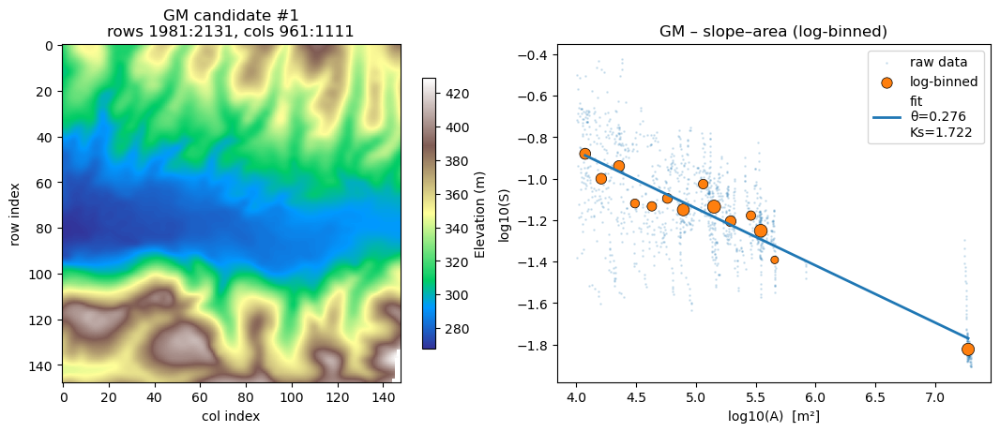


GM – candidate #2   (RMS = 0.510542)
Tile: rows 2011:2161, cols 931:1081   (1480 m × 1480 m)

Results:
  Outlets: 55   Divides: 725   Valid curvatures: 650
  Median D: 1.39e-02 m²/yr  (IQR 8.4e-03–2.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.57  (Taylor  11.80)
  Ks (m):  1.562  (Taylor  1.467)
  θ      :  0.272  (Taylor  0.350)

Individual errors:
  Curvature:  +10.4%   Ks:   +6.5%   θ:  -22.2%
  3-term RMS error: 0.253347


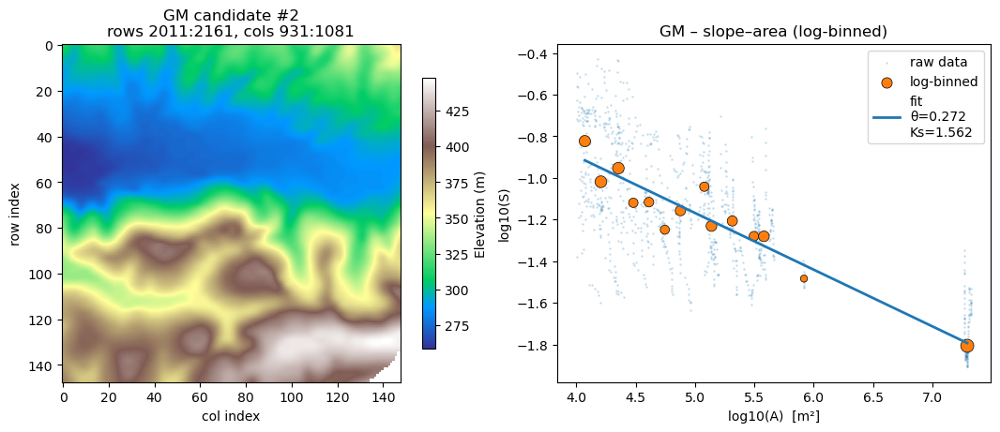


GM – candidate #3   (RMS = 0.521362)
Tile: rows 1951:2101, cols 811:961   (1480 m × 1480 m)

Results:
  Outlets: 52   Divides: 681   Valid curvatures: 622
  Median D: 1.53e-02 m²/yr  (IQR 9.5e-03–2.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.61  (Taylor  11.80)
  Ks (m):  1.864  (Taylor  1.467)
  θ      :  0.287  (Taylor  0.350)

Individual errors:
  Curvature:  +18.5%   Ks:  +27.1%   θ:  -18.1%
  3-term RMS error: 0.374713


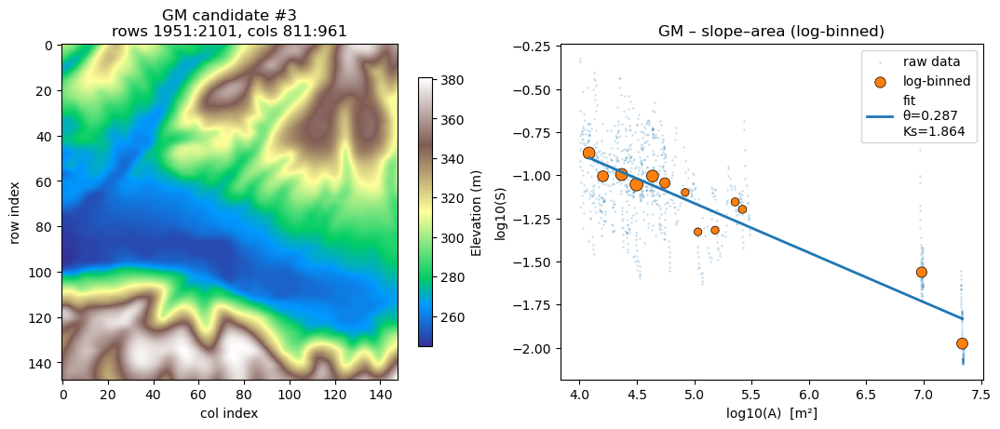


GM – candidate #4   (RMS = 0.523732)
Tile: rows 2011:2161, cols 961:1111   (1480 m × 1480 m)

Results:
  Outlets: 49   Divides: 675   Valid curvatures: 568
  Median D: 1.30e-02 m²/yr  (IQR 7.7e-03–2.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.31  (Taylor  11.80)
  Ks (m):  1.937  (Taylor  1.467)
  θ      :  0.286  (Taylor  0.350)

Individual errors:
  Curvature:   +4.1%   Ks:  +32.1%   θ:  -18.4%
  3-term RMS error: 0.372097


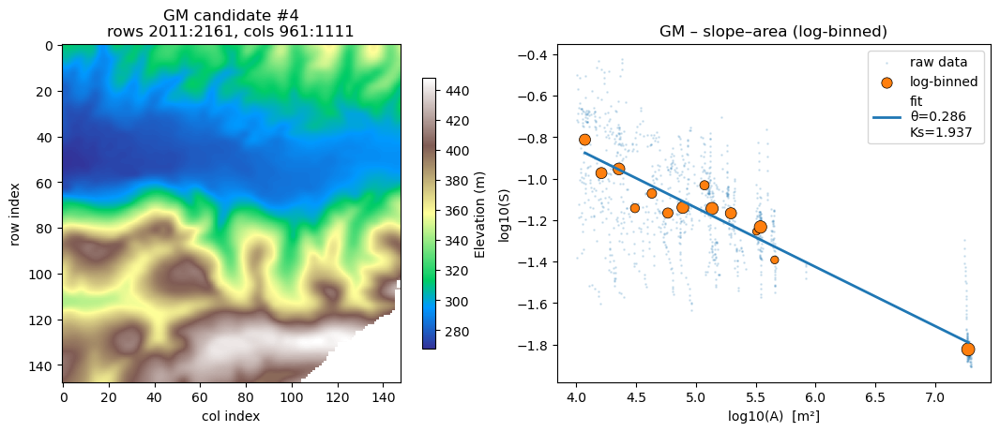


GM – candidate #5   (RMS = 0.530253)
Tile: rows 1981:2131, cols 931:1081   (1480 m × 1480 m)

Results:
  Outlets: 52   Divides: 588   Valid curvatures: 541
  Median D: 1.39e-02 m²/yr  (IQR 8.3e-03–2.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.61  (Taylor  11.80)
  Ks (m):  1.528  (Taylor  1.467)
  θ      :  0.269  (Taylor  0.350)

Individual errors:
  Curvature:  +10.1%   Ks:   +4.2%   θ:  -23.2%
  3-term RMS error: 0.256548


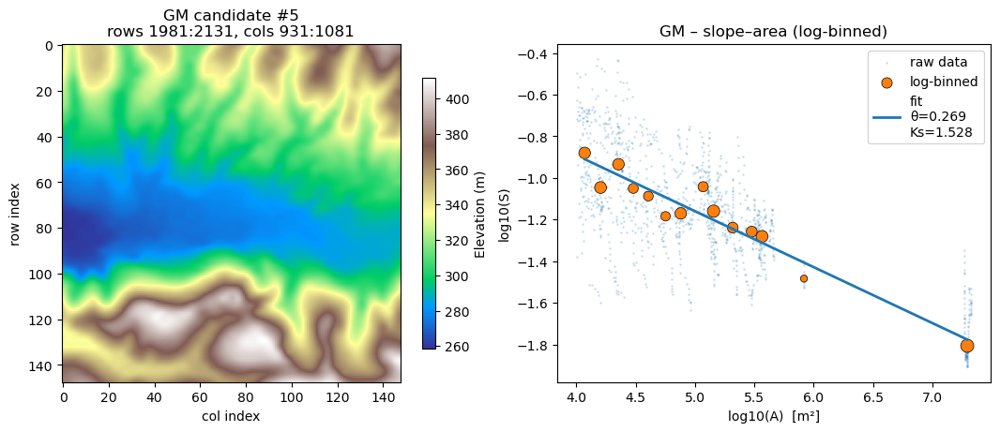


GM – candidate #6   (RMS = 0.535919)
Tile: rows 1921:2071, cols 1081:1231   (1480 m × 1480 m)

Results:
  Outlets: 40   Divides: 474   Valid curvatures: 415
  Median D: 1.35e-02 m²/yr  (IQR 9.3e-03–2.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.88  (Taylor  11.80)
  Ks (m):  1.617  (Taylor  1.467)
  θ      :  0.269  (Taylor  0.350)

Individual errors:
  Curvature:   +7.8%   Ks:  +10.2%   θ:  -23.3%
  3-term RMS error: 0.265951


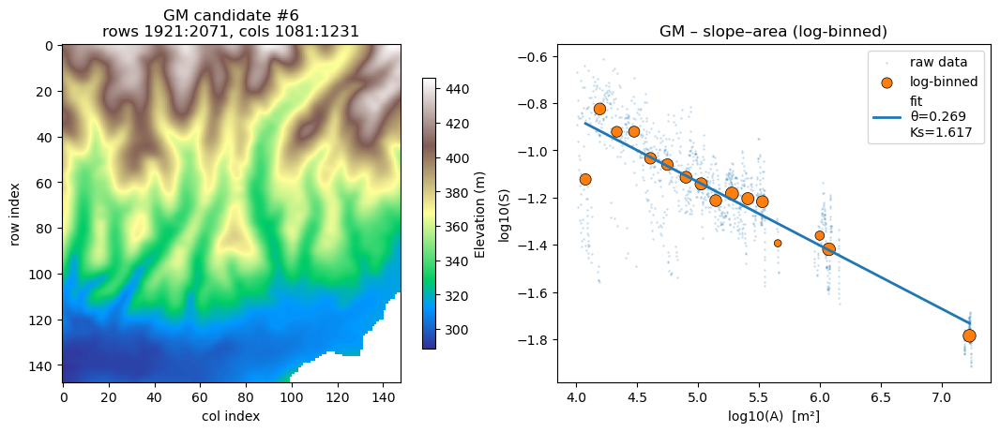


GM – candidate #7   (RMS = 0.537074)
Tile: rows 2011:2161, cols 871:1021   (1480 m × 1480 m)

Results:
  Outlets: 54   Divides: 667   Valid curvatures: 602
  Median D: 1.49e-02 m²/yr  (IQR 8.6e-03–3.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.86  (Taylor  11.80)
  Ks (m):  1.592  (Taylor  1.467)
  θ      :  0.271  (Taylor  0.350)

Individual errors:
  Curvature:  +16.4%   Ks:   +8.5%   θ:  -22.5%
  3-term RMS error: 0.291645


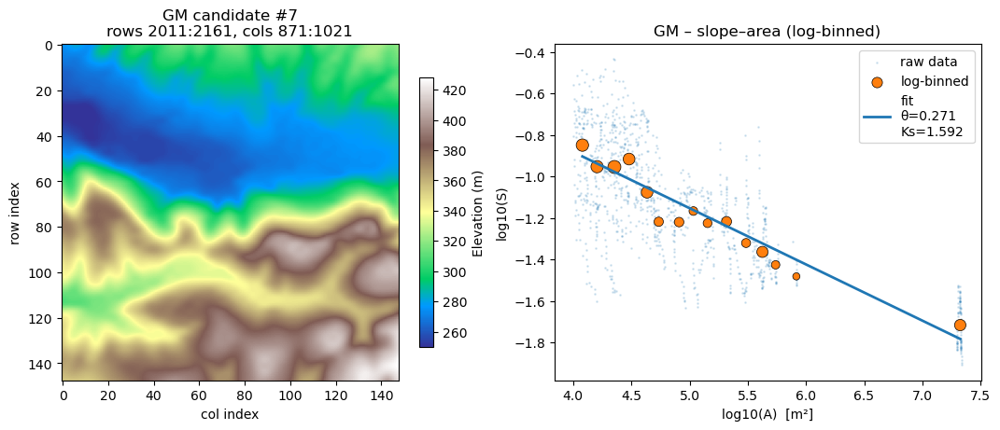


GM – candidate #8   (RMS = 0.538261)
Tile: rows 1921:2071, cols 961:1111   (1480 m × 1480 m)

Results:
  Outlets: 43   Divides: 609   Valid curvatures: 571
  Median D: 1.47e-02 m²/yr  (IQR 9.9e-03–2.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.03  (Taylor  11.80)
  Ks (m):  1.813  (Taylor  1.467)
  θ      :  0.278  (Taylor  0.350)

Individual errors:
  Curvature:  +15.0%   Ks:  +23.6%   θ:  -20.6%
  3-term RMS error: 0.347127


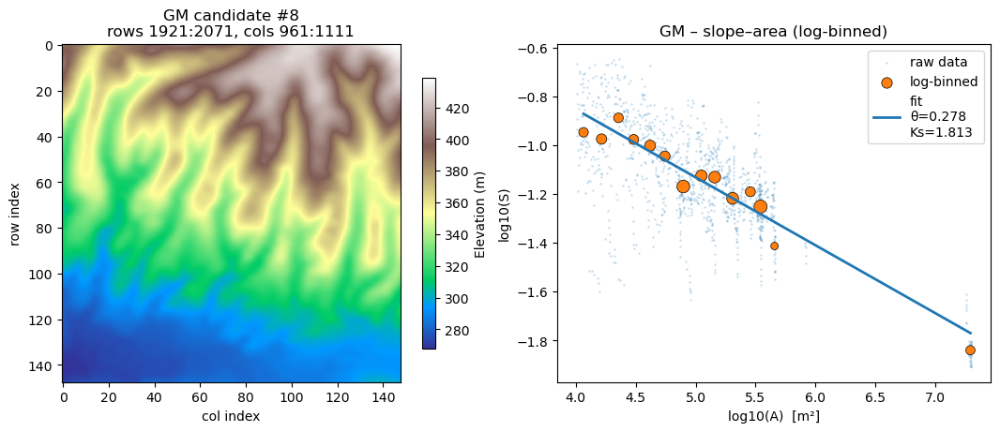


GM – candidate #9   (RMS = 0.538847)
Tile: rows 1951:2101, cols 1051:1201   (1480 m × 1480 m)

Results:
  Outlets: 35   Divides: 484   Valid curvatures: 373
  Median D: 1.30e-02 m²/yr  (IQR 9.0e-03–2.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.28  (Taylor  11.80)
  Ks (m):  1.567  (Taylor  1.467)
  θ      :  0.267  (Taylor  0.350)

Individual errors:
  Curvature:   +4.4%   Ks:   +6.8%   θ:  -23.8%
  3-term RMS error: 0.251581


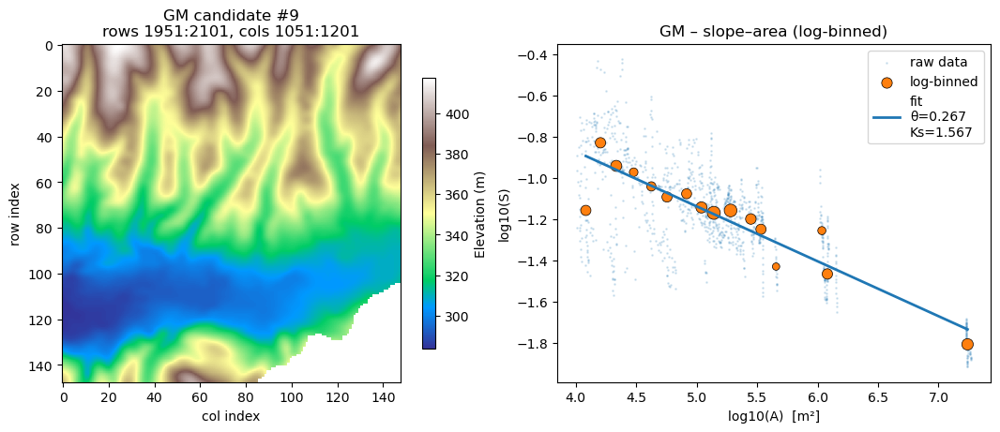


GM – candidate #10   (RMS = 0.540045)
Tile: rows 1951:2101, cols 961:1111   (1480 m × 1480 m)

Results:
  Outlets: 42   Divides: 545   Valid curvatures: 502
  Median D: 1.35e-02 m²/yr  (IQR 8.4e-03–2.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.87  (Taylor  11.80)
  Ks (m):  1.952  (Taylor  1.467)
  θ      :  0.284  (Taylor  0.350)

Individual errors:
  Curvature:   +7.9%   Ks:  +33.1%   θ:  -18.8%
  3-term RMS error: 0.388470


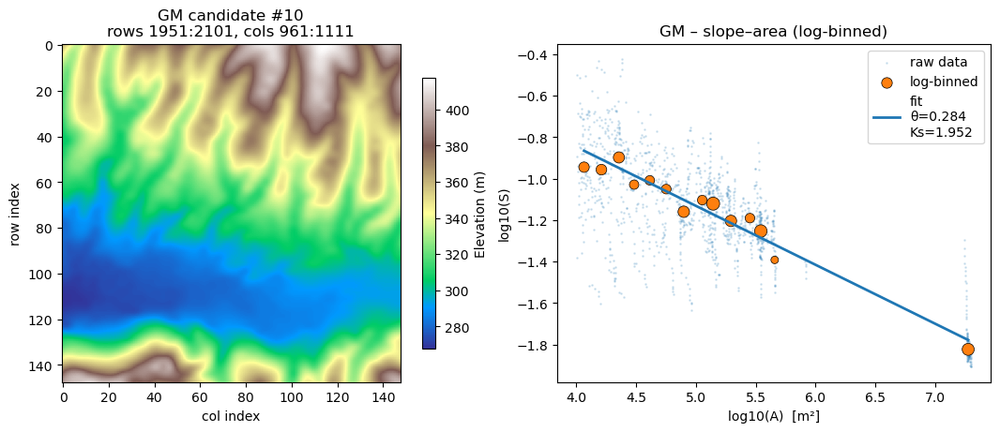


GM – candidate #11   (RMS = 0.543486)
Tile: rows 1921:2071, cols 931:1081   (1480 m × 1480 m)

Results:
  Outlets: 45   Divides: 664   Valid curvatures: 626
  Median D: 1.55e-02 m²/yr  (IQR 1.0e-02–2.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.47  (Taylor  11.80)
  Ks (m):  1.634  (Taylor  1.467)
  θ      :  0.273  (Taylor  0.350)

Individual errors:
  Curvature:  +19.8%   Ks:  +11.4%   θ:  -22.1%
  3-term RMS error: 0.317364


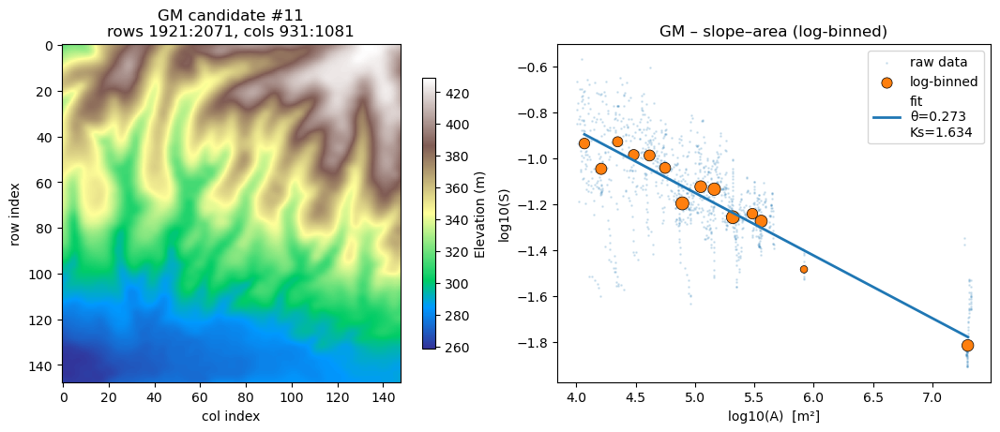


GM – candidate #12   (RMS = 0.544633)
Tile: rows 1951:2101, cols 931:1081   (1480 m × 1480 m)

Results:
  Outlets: 46   Divides: 543   Valid curvatures: 503
  Median D: 1.58e-02 m²/yr  (IQR 9.2e-03–2.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.33  (Taylor  11.80)
  Ks (m):  1.684  (Taylor  1.467)
  θ      :  0.275  (Taylor  0.350)

Individual errors:
  Curvature:  +21.0%   Ks:  +14.8%   θ:  -21.5%
  3-term RMS error: 0.334709


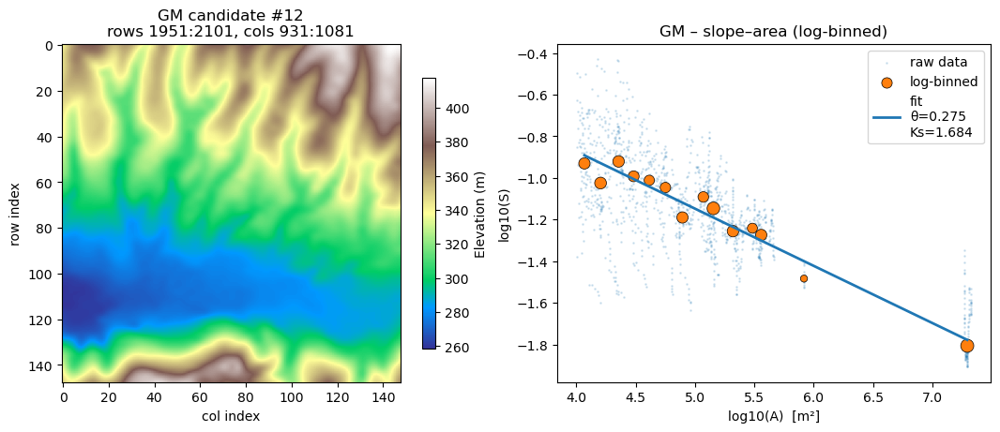


GM – candidate #13   (RMS = 0.545123)
Tile: rows 1921:2071, cols 811:961   (1480 m × 1480 m)

Results:
  Outlets: 50   Divides: 536   Valid curvatures: 500
  Median D: 1.59e-02 m²/yr  (IQR 9.8e-03–2.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.22  (Taylor  11.80)
  Ks (m):  1.896  (Taylor  1.467)
  θ      :  0.287  (Taylor  0.350)

Individual errors:
  Curvature:  +21.9%   Ks:  +29.2%   θ:  -18.1%
  3-term RMS error: 0.407342


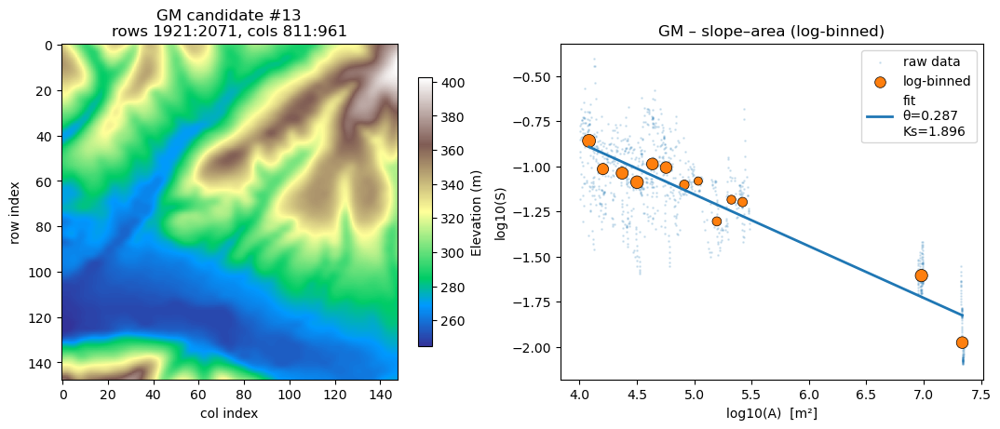


GM – candidate #14   (RMS = 0.547472)
Tile: rows 2011:2161, cols 841:991   (1480 m × 1480 m)

Results:
  Outlets: 55   Divides: 621   Valid curvatures: 563
  Median D: 1.51e-02 m²/yr  (IQR 9.4e-03–3.0e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.72  (Taylor  11.80)
  Ks (m):  1.895  (Taylor  1.467)
  θ      :  0.283  (Taylor  0.350)

Individual errors:
  Curvature:  +17.6%   Ks:  +29.1%   θ:  -19.2%
  3-term RMS error: 0.390705


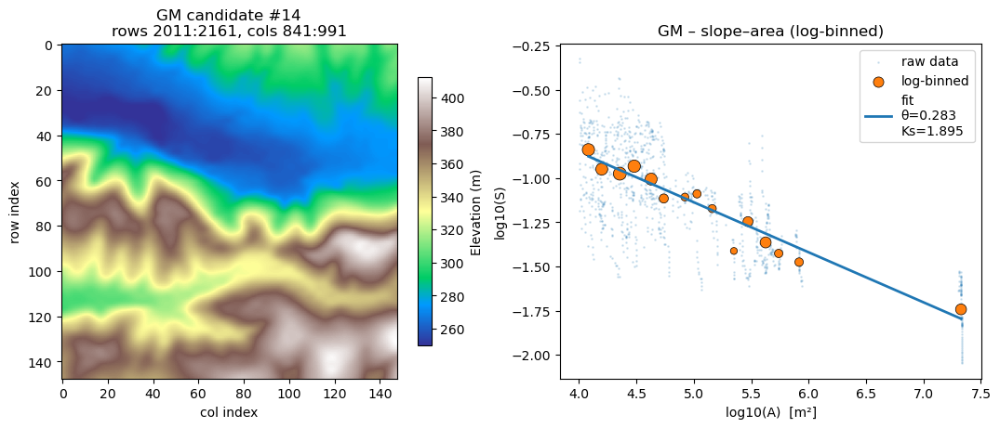


GM – candidate #15   (RMS = 0.548629)
Tile: rows 1921:2071, cols 1051:1201   (1480 m × 1480 m)

Results:
  Outlets: 41   Divides: 474   Valid curvatures: 427
  Median D: 1.34e-02 m²/yr  (IQR 9.5e-03–2.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.00  (Taylor  11.80)
  Ks (m):  1.960  (Taylor  1.467)
  θ      :  0.283  (Taylor  0.350)

Individual errors:
  Curvature:   +6.8%   Ks:  +33.6%   θ:  -19.1%
  3-term RMS error: 0.392829


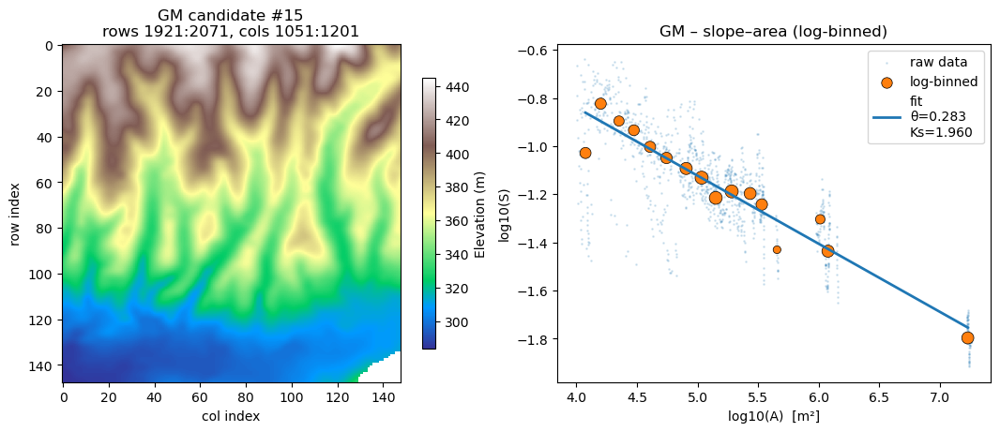


GM – candidate #16   (RMS = 0.549534)
Tile: rows 1981:2131, cols 841:991   (1480 m × 1480 m)

Results:
  Outlets: 54   Divides: 606   Valid curvatures: 550
  Median D: 1.53e-02 m²/yr  (IQR 9.6e-03–2.9e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.59  (Taylor  11.80)
  Ks (m):  1.625  (Taylor  1.467)
  θ      :  0.271  (Taylor  0.350)

Individual errors:
  Curvature:  +18.7%   Ks:  +10.8%   θ:  -22.6%
  3-term RMS error: 0.312694


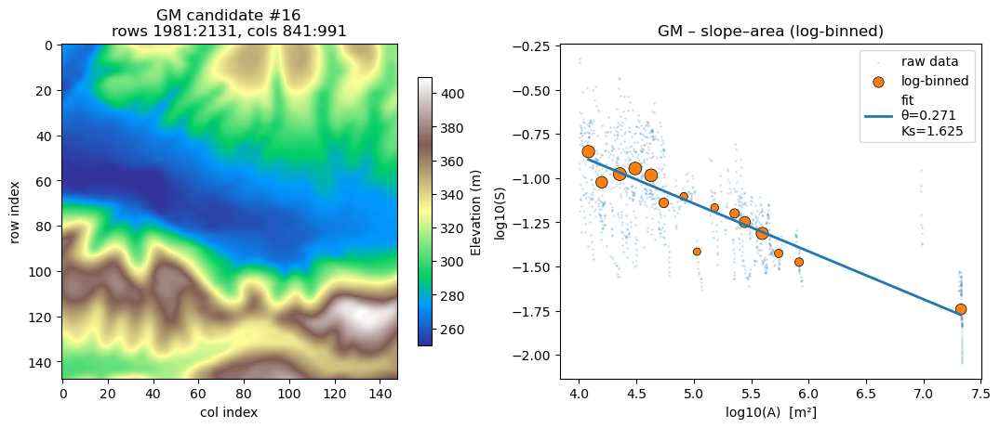


GM – candidate #17   (RMS = 0.555781)
Tile: rows 1891:2041, cols 961:1111   (1480 m × 1480 m)

Results:
  Outlets: 44   Divides: 745   Valid curvatures: 700
  Median D: 1.29e-02 m²/yr  (IQR 9.4e-03–2.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.41  (Taylor  11.80)
  Ks (m):  1.890  (Taylor  1.467)
  θ      :  0.276  (Taylor  0.350)

Individual errors:
  Curvature:   +3.3%   Ks:  +28.9%   θ:  -21.2%
  3-term RMS error: 0.359531


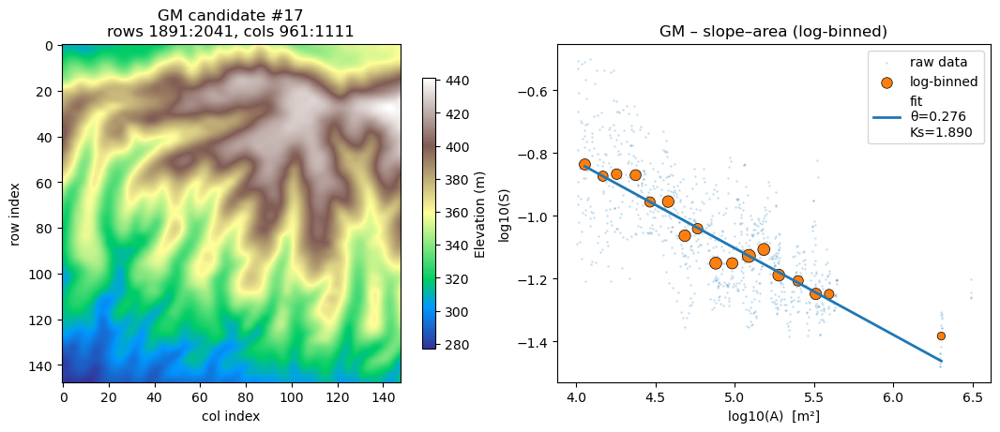


GM – candidate #18   (RMS = 0.565072)
Tile: rows 1861:2011, cols 901:1051   (1480 m × 1480 m)

Results:
  Outlets: 44   Divides: 681   Valid curvatures: 648
  Median D: 1.14e-02 m²/yr  (IQR 8.4e-03–1.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -12.85  (Taylor  11.80)
  Ks (m):  1.689  (Taylor  1.467)
  θ      :  0.266  (Taylor  0.350)

Individual errors:
  Curvature:   -8.9%   Ks:  +15.1%   θ:  -24.0%
  3-term RMS error: 0.297343


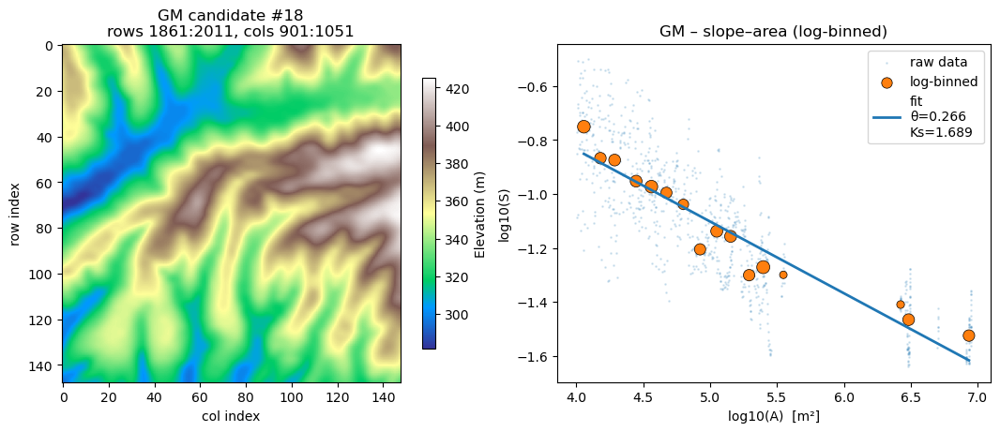


GM – candidate #19   (RMS = 0.568981)
Tile: rows 1981:2131, cols 781:931   (1480 m × 1480 m)

Results:
  Outlets: 51   Divides: 682   Valid curvatures: 619
  Median D: 1.44e-02 m²/yr  (IQR 9.1e-03–2.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.22  (Taylor  11.80)
  Ks (m):  1.483  (Taylor  1.467)
  θ      :  0.263  (Taylor  0.350)

Individual errors:
  Curvature:  +13.4%   Ks:   +1.1%   θ:  -24.7%
  3-term RMS error: 0.281357


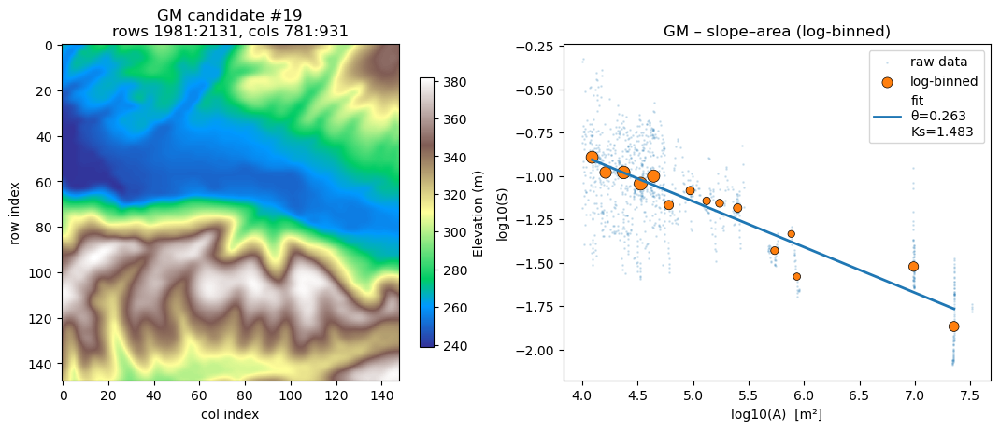


GM – candidate #20   (RMS = 0.577994)
Tile: rows 1891:2041, cols 901:1051   (1480 m × 1480 m)

Results:
  Outlets: 49   Divides: 719   Valid curvatures: 685
  Median D: 1.27e-02 m²/yr  (IQR 9.0e-03–2.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.55  (Taylor  11.80)
  Ks (m):  1.591  (Taylor  1.467)
  θ      :  0.261  (Taylor  0.350)

Individual errors:
  Curvature:   +2.1%   Ks:   +8.4%   θ:  -25.6%
  3-term RMS error: 0.269930


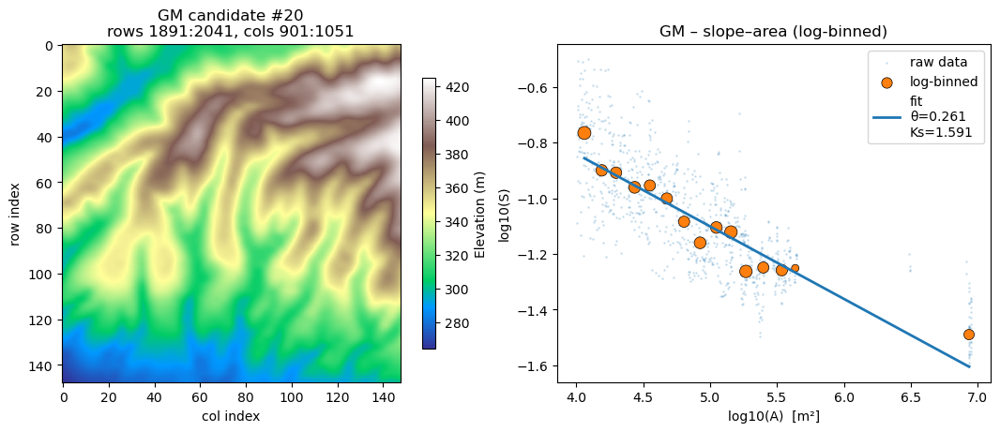


GM – candidate #21   (RMS = 0.581877)
Tile: rows 2011:2161, cols 721:871   (1480 m × 1480 m)

Results:
  Outlets: 52   Divides: 759   Valid curvatures: 714
  Median D: 1.32e-02 m²/yr  (IQR 8.8e-03–2.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.17  (Taylor  11.80)
  Ks (m):  2.057  (Taylor  1.467)
  θ      :  0.285  (Taylor  0.350)

Individual errors:
  Curvature:   +5.3%   Ks:  +40.2%   θ:  -18.7%
  3-term RMS error: 0.446318


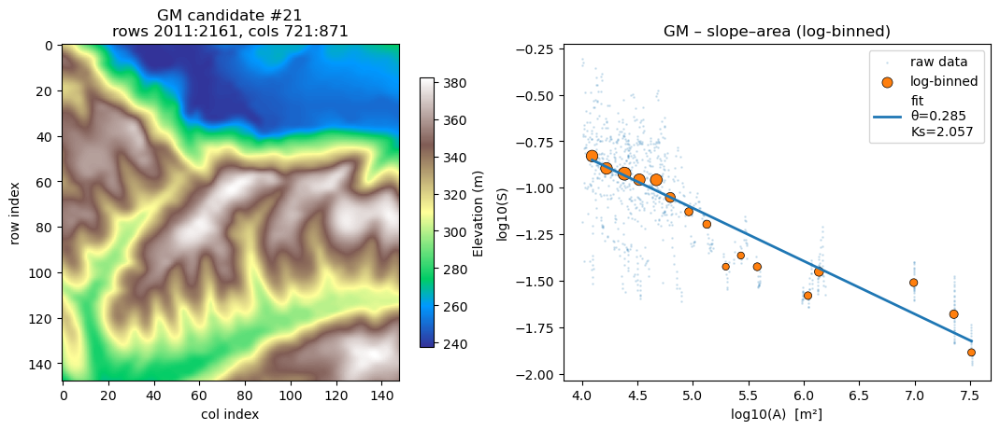


GM – candidate #22   (RMS = 0.589971)
Tile: rows 1891:2041, cols 991:1141   (1480 m × 1480 m)

Results:
  Outlets: 47   Divides: 853   Valid curvatures: 799
  Median D: 1.26e-02 m²/yr  (IQR 9.4e-03–2.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.70  (Taylor  11.80)
  Ks (m):  1.937  (Taylor  1.467)
  θ      :  0.272  (Taylor  0.350)

Individual errors:
  Curvature:   +0.9%   Ks:  +32.0%   θ:  -22.2%
  3-term RMS error: 0.389410


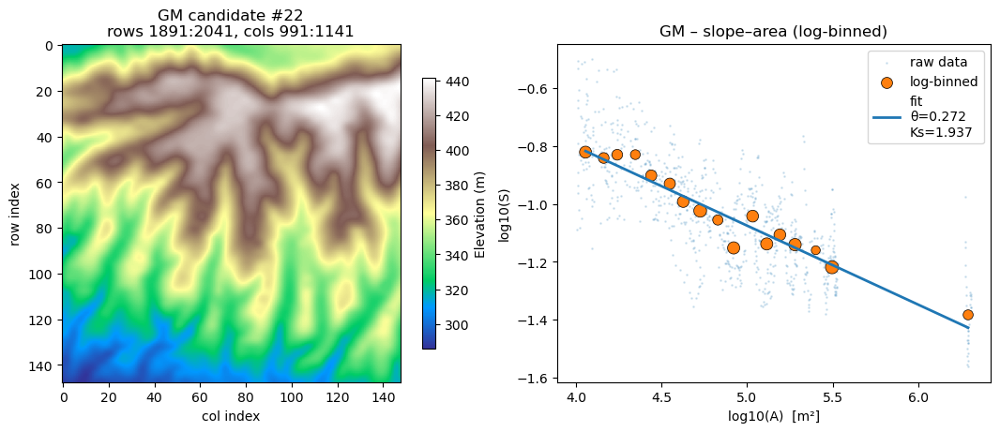


GM – candidate #23   (RMS = 0.592751)
Tile: rows 1831:1981, cols 901:1051   (1480 m × 1480 m)

Results:
  Outlets: 50   Divides: 729   Valid curvatures: 687
  Median D: 1.07e-02 m²/yr  (IQR 8.2e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -13.80  (Taylor  11.80)
  Ks (m):  1.617  (Taylor  1.467)
  θ      :  0.263  (Taylor  0.350)

Individual errors:
  Curvature:  -16.9%   Ks:  +10.2%   θ:  -25.0%
  3-term RMS error: 0.318612


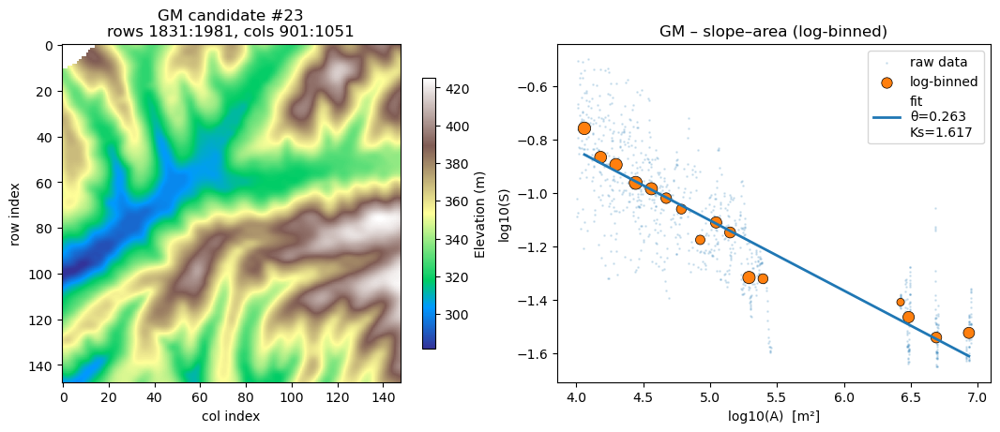


GM – candidate #24   (RMS = 0.594529)
Tile: rows 1951:2101, cols 1021:1171   (1480 m × 1480 m)

Results:
  Outlets: 37   Divides: 517   Valid curvatures: 426
  Median D: 1.28e-02 m²/yr  (IQR 8.7e-03–2.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.47  (Taylor  11.80)
  Ks (m):  2.120  (Taylor  1.467)
  θ      :  0.288  (Taylor  0.350)

Individual errors:
  Curvature:   +2.8%   Ks:  +44.5%   θ:  -17.6%
  3-term RMS error: 0.479531


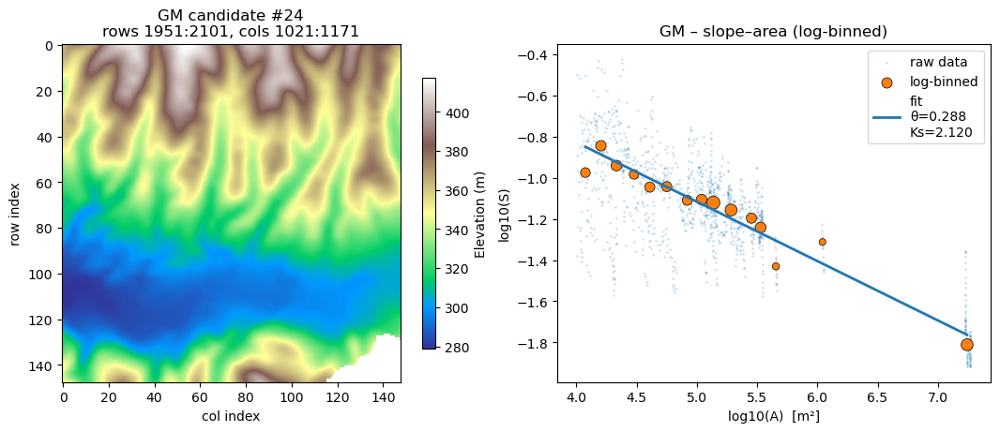


GM – candidate #25   (RMS = 0.601104)
Tile: rows 1981:2131, cols 691:841   (1480 m × 1480 m)

Results:
  Outlets: 57   Divides: 876   Valid curvatures: 806
  Median D: 1.62e-02 m²/yr  (IQR 9.6e-03–2.9e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.08  (Taylor  11.80)
  Ks (m):  1.545  (Taylor  1.467)
  θ      :  0.263  (Taylor  0.350)

Individual errors:
  Curvature:  +23.0%   Ks:   +5.3%   θ:  -24.7%
  3-term RMS error: 0.341986


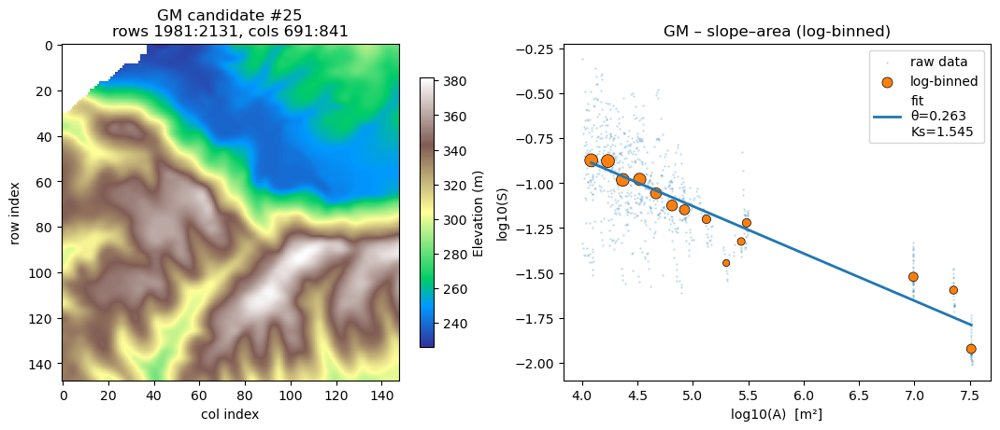


GM – candidate #26   (RMS = 0.602235)
Tile: rows 2011:2161, cols 631:781   (1480 m × 1480 m)

Results:
  Outlets: 49   Divides: 960   Valid curvatures: 898
  Median D: 1.59e-02 m²/yr  (IQR 9.9e-03–3.0e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.27  (Taylor  11.80)
  Ks (m):  1.882  (Taylor  1.467)
  θ      :  0.274  (Taylor  0.350)

Individual errors:
  Curvature:  +21.4%   Ks:  +28.3%   θ:  -21.8%
  3-term RMS error: 0.416328


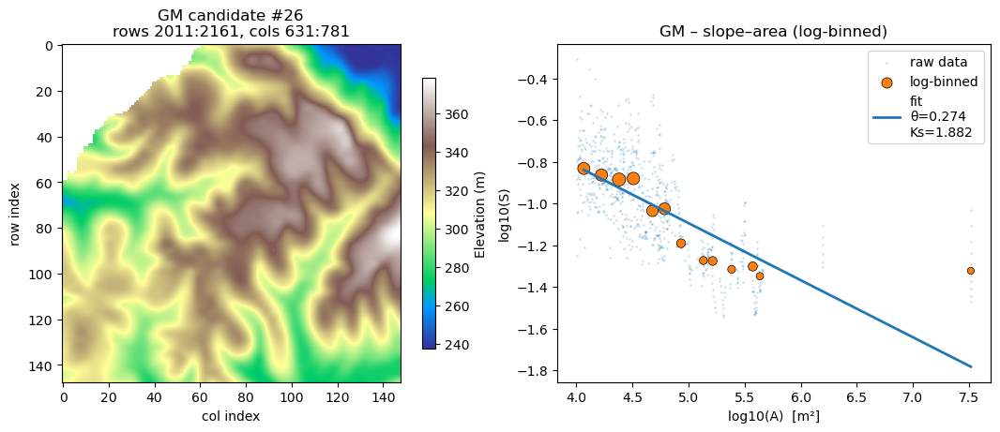


GM – candidate #27   (RMS = 0.604370)
Tile: rows 1981:2131, cols 751:901   (1480 m × 1480 m)

Results:
  Outlets: 58   Divides: 746   Valid curvatures: 678
  Median D: 1.38e-02 m²/yr  (IQR 8.9e-03–2.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.64  (Taylor  11.80)
  Ks (m):  1.431  (Taylor  1.467)
  θ      :  0.257  (Taylor  0.350)

Individual errors:
  Curvature:   +9.9%   Ks:   -2.5%   θ:  -26.6%
  3-term RMS error: 0.285197


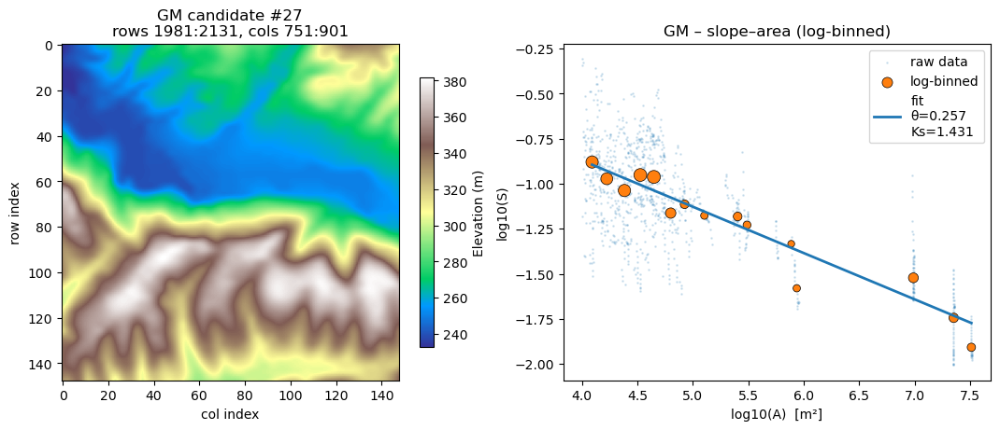


GM – candidate #28   (RMS = 0.604905)
Tile: rows 2011:2161, cols 901:1051   (1480 m × 1480 m)

Results:
  Outlets: 55   Divides: 676   Valid curvatures: 608
  Median D: 1.45e-02 m²/yr  (IQR 8.4e-03–3.0e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.13  (Taylor  11.80)
  Ks (m):  1.361  (Taylor  1.467)
  θ      :  0.259  (Taylor  0.350)

Individual errors:
  Curvature:  +14.1%   Ks:   -7.2%   θ:  -26.1%
  3-term RMS error: 0.305470


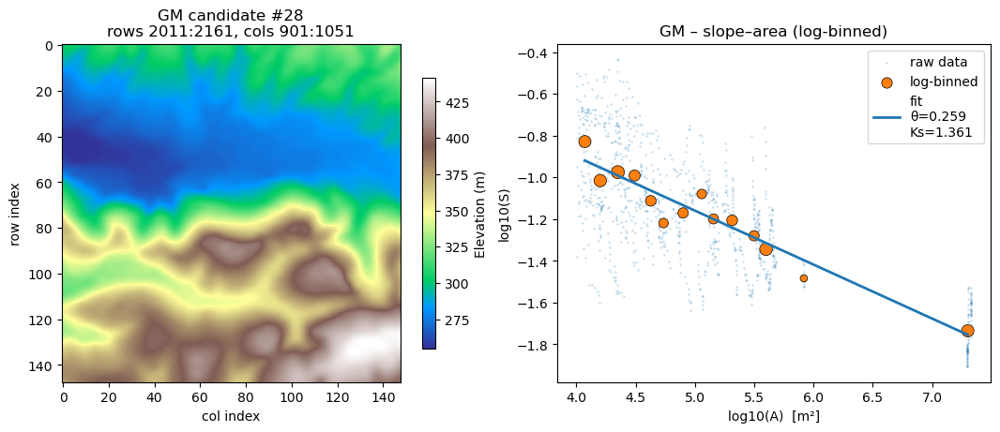


GM – candidate #29   (RMS = 0.610976)
Tile: rows 1861:2011, cols 871:1021   (1480 m × 1480 m)

Results:
  Outlets: 43   Divides: 615   Valid curvatures: 577
  Median D: 1.15e-02 m²/yr  (IQR 8.3e-03–1.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -12.75  (Taylor  11.80)
  Ks (m):  1.431  (Taylor  1.467)
  θ      :  0.255  (Taylor  0.350)

Individual errors:
  Curvature:   -8.0%   Ks:   -2.4%   θ:  -27.1%
  3-term RMS error: 0.283320


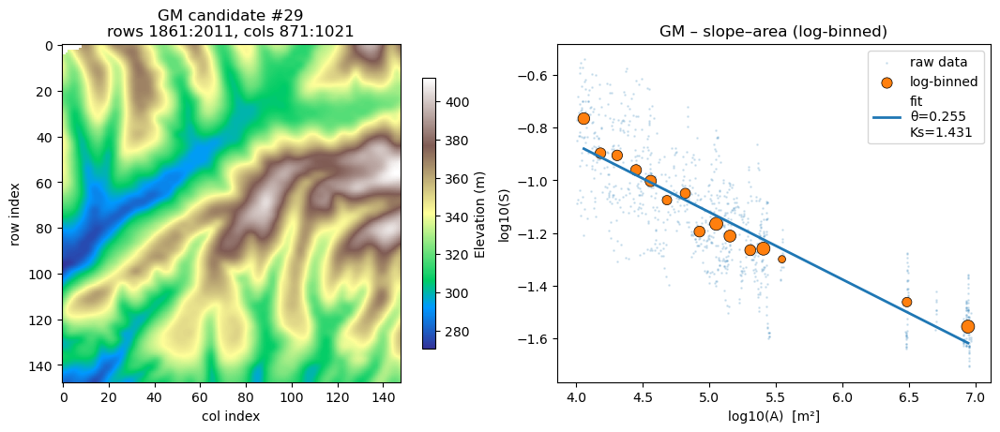


GM – candidate #30   (RMS = 0.614551)
Tile: rows 2041:2191, cols 871:1021   (1480 m × 1480 m)

Results:
  Outlets: 50   Divides: 682   Valid curvatures: 626
  Median D: 1.47e-02 m²/yr  (IQR 8.6e-03–2.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.00  (Taylor  11.80)
  Ks (m):  2.180  (Taylor  1.467)
  θ      :  0.296  (Taylor  0.350)

Individual errors:
  Curvature:  +15.3%   Ks:  +48.6%   θ:  -15.4%
  3-term RMS error: 0.532078


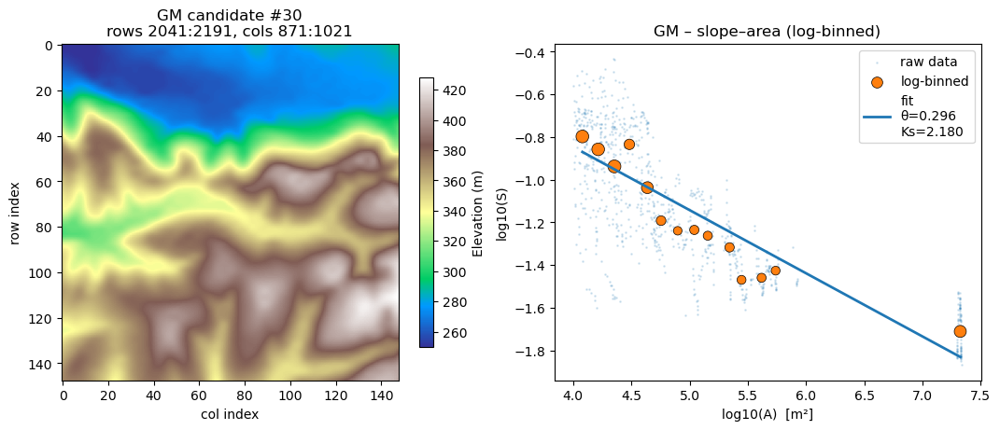

Loaded AP dataset: (1314, 1801) pixels

AP – candidate #1   (RMS = 0.031842)
Tile: rows 771:821, cols 991:1041   (1440 m × 1440 m)

Results:
  Outlets: 11   Divides: 82   Valid curvatures: 81
  Median D: 1.01e-02 m²/yr  (IQR 6.5e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.47  (Taylor   5.50)
  Ks (m):  4.521  (Taylor  4.400)
  θ      :  0.368  (Taylor  0.370)

Individual errors:
  Curvature:   +0.6%   Ks:   +2.8%   θ:   -0.7%
  3-term RMS error: 0.028935


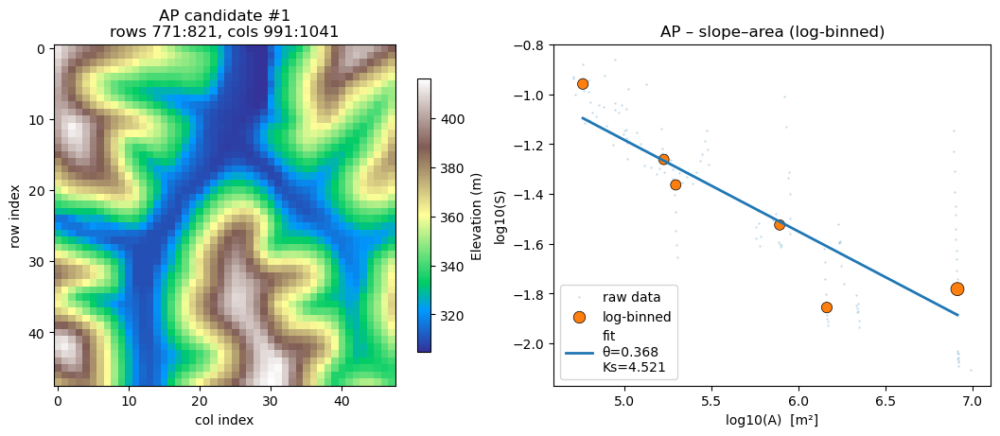


AP – candidate #2   (RMS = 0.032881)
Tile: rows 1111:1161, cols 1361:1411   (1440 m × 1440 m)

Results:
  Outlets: 13   Divides: 105   Valid curvatures: 85
  Median D: 1.03e-02 m²/yr  (IQR 7.0e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.36  (Taylor   5.50)
  Ks (m):  4.487  (Taylor  4.400)
  θ      :  0.369  (Taylor  0.370)

Individual errors:
  Curvature:   +2.6%   Ks:   +2.0%   θ:   -0.2%
  3-term RMS error: 0.032571


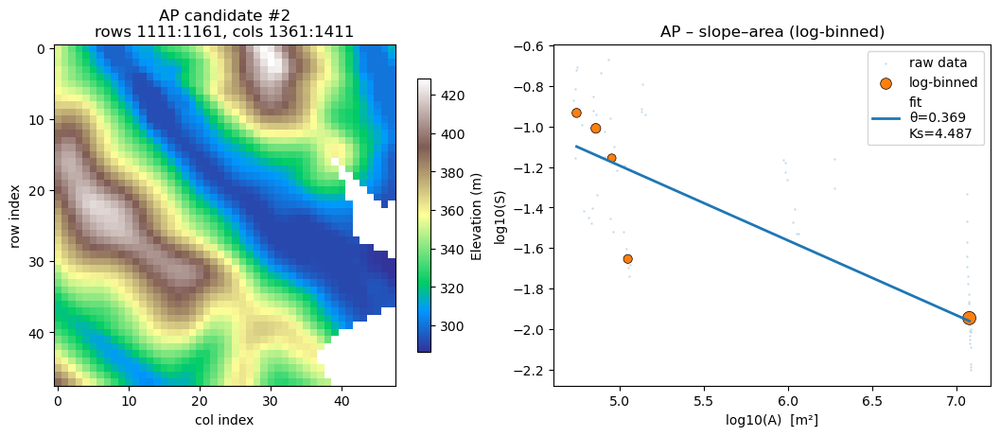


AP – candidate #3   (RMS = 0.053381)
Tile: rows 321:371, cols 751:801   (1440 m × 1440 m)

Results:
  Outlets: 12   Divides: 133   Valid curvatures: 126
  Median D: 1.00e-02 m²/yr  (IQR 6.8e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.50  (Taylor   5.50)
  Ks (m):  4.315  (Taylor  4.400)
  θ      :  0.362  (Taylor  0.370)

Individual errors:
  Curvature:   -0.0%   Ks:   -1.9%   θ:   -2.2%
  3-term RMS error: 0.029516


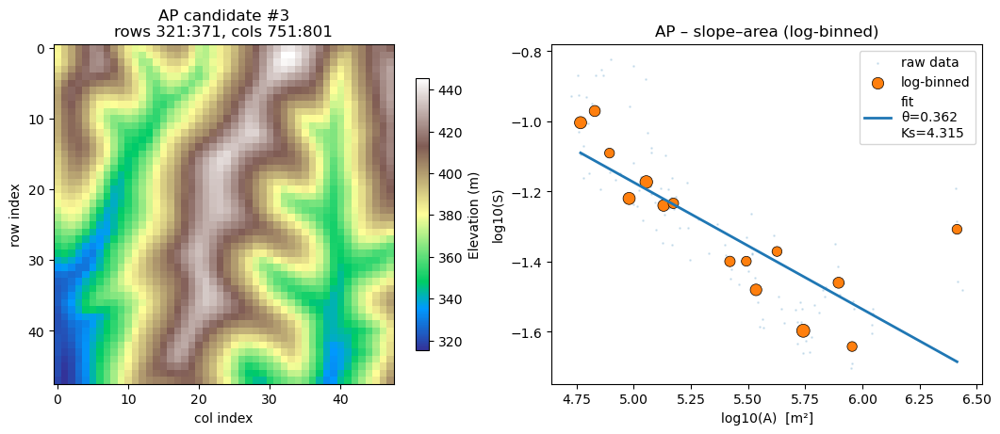


AP – candidate #4   (RMS = 0.069390)
Tile: rows 1061:1111, cols 1471:1521   (1440 m × 1440 m)

Results:
  Outlets: 11   Divides: 151   Valid curvatures: 145
  Median D: 9.72e-03 m²/yr  (IQR 6.7e-03–1.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.66  (Taylor   5.50)
  Ks (m):  4.365  (Taylor  4.400)
  θ      :  0.360  (Taylor  0.370)

Individual errors:
  Curvature:   -2.8%   Ks:   -0.8%   θ:   -2.8%
  3-term RMS error: 0.040743


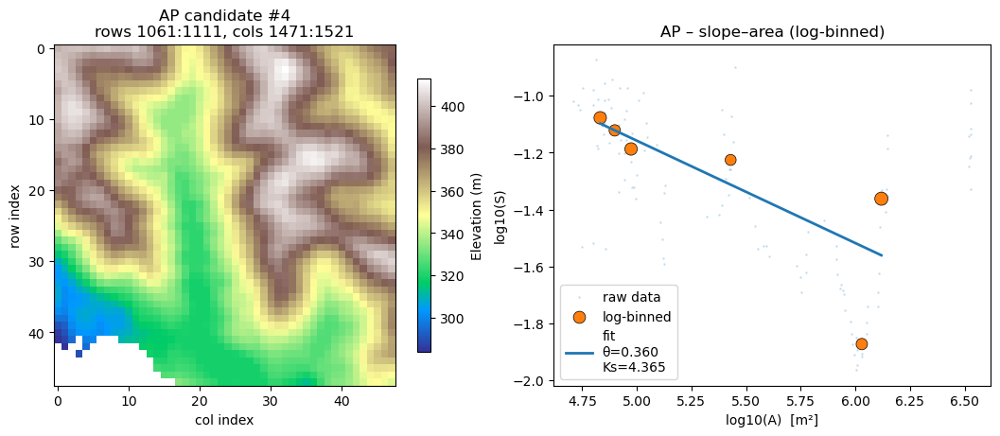


AP – candidate #5   (RMS = 0.073680)
Tile: rows 301:351, cols 761:811   (1440 m × 1440 m)

Results:
  Outlets: 11   Divides: 151   Valid curvatures: 147
  Median D: 9.89e-03 m²/yr  (IQR 7.3e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.56  (Taylor   5.50)
  Ks (m):  4.150  (Taylor  4.400)
  θ      :  0.362  (Taylor  0.370)

Individual errors:
  Curvature:   -1.1%   Ks:   -5.7%   θ:   -2.0%
  3-term RMS error: 0.061310


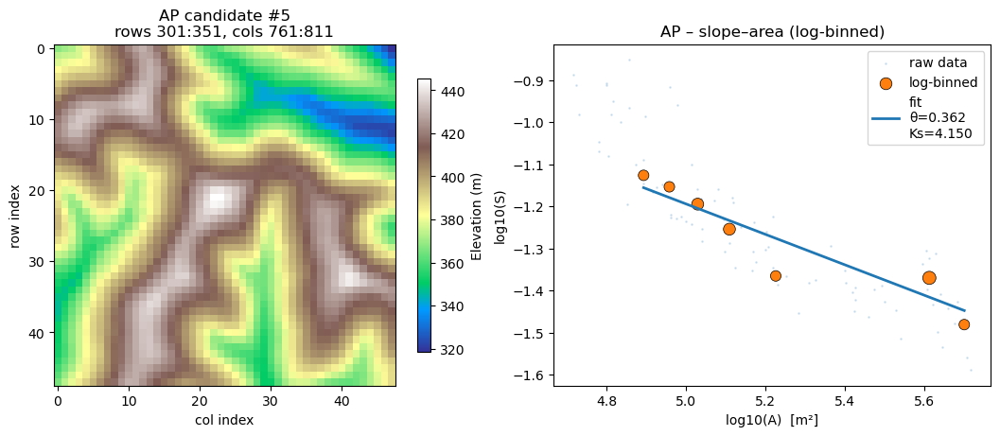


AP – candidate #6   (RMS = 0.078606)
Tile: rows 621:671, cols 661:711   (1440 m × 1440 m)

Results:
  Outlets: 12   Divides: 123   Valid curvatures: 114
  Median D: 9.40e-03 m²/yr  (IQR 6.8e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.85  (Taylor   5.50)
  Ks (m):  4.428  (Taylor  4.400)
  θ      :  0.378  (Taylor  0.370)

Individual errors:
  Curvature:   -6.4%   Ks:   +0.6%   θ:   +2.0%
  3-term RMS error: 0.067134


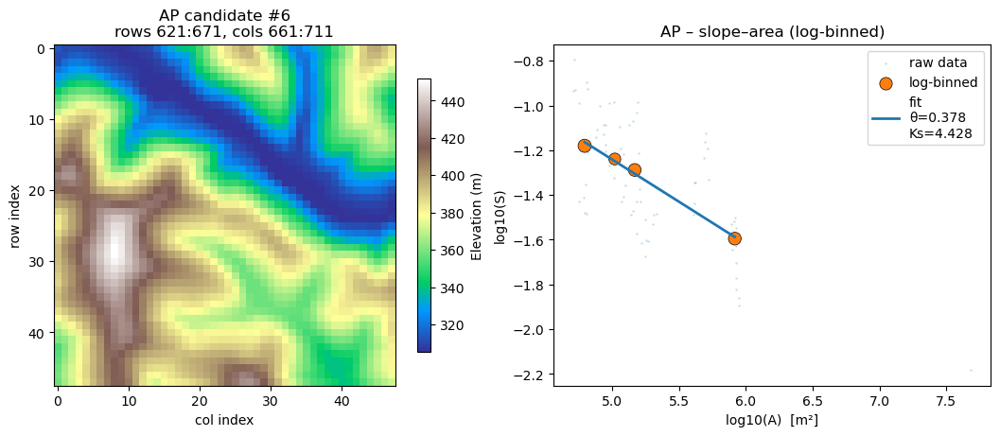


AP – candidate #7   (RMS = 0.082842)
Tile: rows 221:271, cols 751:801   (1440 m × 1440 m)

Results:
  Outlets: 10   Divides: 60   Valid curvatures: 59
  Median D: 9.49e-03 m²/yr  (IQR 6.5e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.80  (Taylor   5.50)
  Ks (m):  4.668  (Taylor  4.400)
  θ      :  0.368  (Taylor  0.370)

Individual errors:
  Curvature:   -5.4%   Ks:   +6.1%   θ:   -0.7%
  3-term RMS error: 0.081796


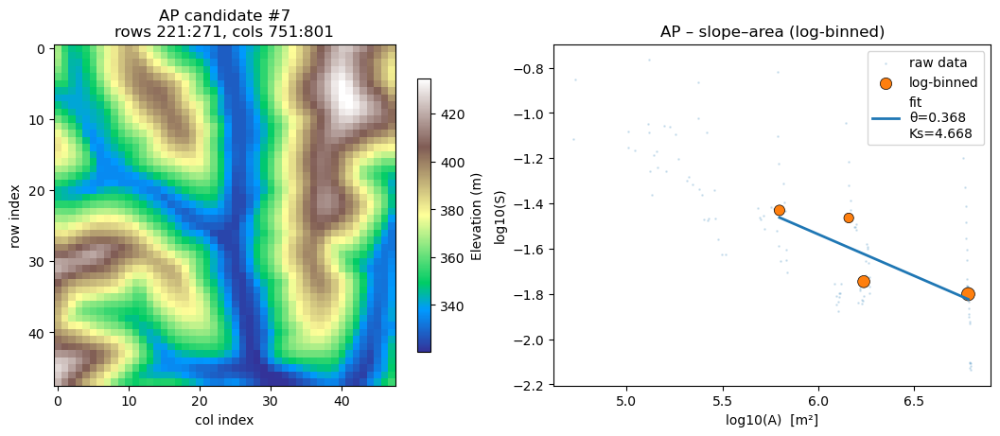


AP – candidate #8   (RMS = 0.085550)
Tile: rows 581:631, cols 661:711   (1440 m × 1440 m)

Results:
  Outlets: 12   Divides: 119   Valid curvatures: 114
  Median D: 9.42e-03 m²/yr  (IQR 6.6e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.84  (Taylor   5.50)
  Ks (m):  4.546  (Taylor  4.400)
  θ      :  0.362  (Taylor  0.370)

Individual errors:
  Curvature:   -6.1%   Ks:   +3.3%   θ:   -2.2%
  3-term RMS error: 0.073320


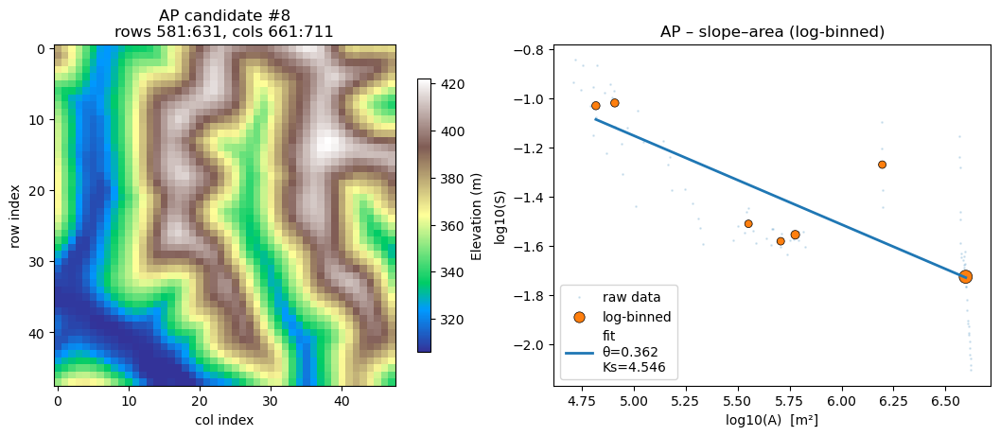


AP – candidate #9   (RMS = 0.091744)
Tile: rows 731:781, cols 891:941   (1440 m × 1440 m)

Results:
  Outlets: 10   Divides: 96   Valid curvatures: 96
  Median D: 9.63e-03 m²/yr  (IQR 7.1e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.71  (Taylor   5.50)
  Ks (m):  4.654  (Taylor  4.400)
  θ      :  0.360  (Taylor  0.370)

Individual errors:
  Curvature:   -3.9%   Ks:   +5.8%   θ:   -2.7%
  3-term RMS error: 0.074548


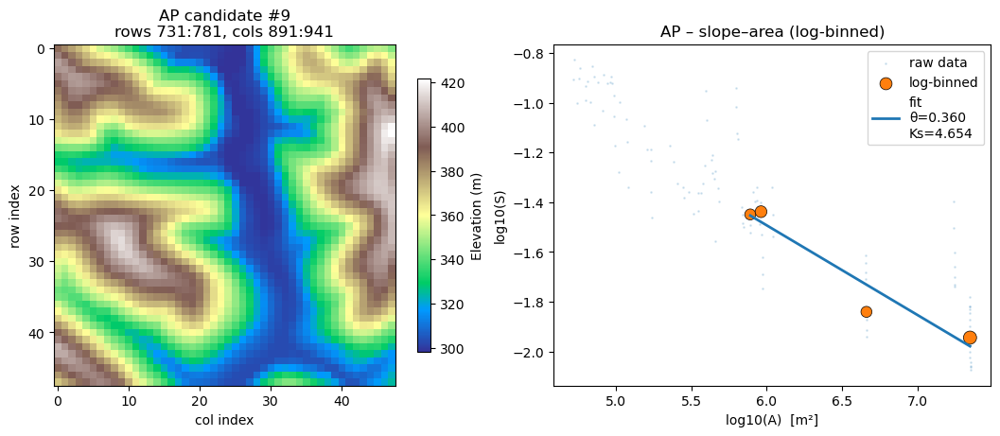


AP – candidate #10   (RMS = 0.098435)
Tile: rows 351:401, cols 551:601   (1440 m × 1440 m)

Results:
  Outlets: 9   Divides: 127   Valid curvatures: 80
  Median D: 9.71e-03 m²/yr  (IQR 6.4e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.67  (Taylor   5.50)
  Ks (m):  4.050  (Taylor  4.400)
  θ      :  0.362  (Taylor  0.370)

Individual errors:
  Curvature:   -3.1%   Ks:   -8.0%   θ:   -2.2%
  3-term RMS error: 0.088111


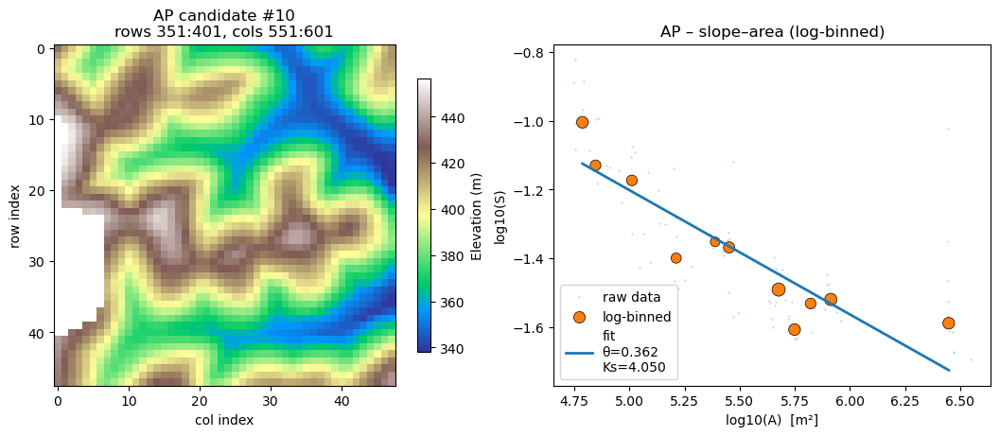


AP – candidate #11   (RMS = 0.098761)
Tile: rows 941:991, cols 851:901   (1440 m × 1440 m)

Results:
  Outlets: 9   Divides: 115   Valid curvatures: 108
  Median D: 9.39e-03 m²/yr  (IQR 5.8e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.86  (Taylor   5.50)
  Ks (m):  4.224  (Taylor  4.400)
  θ      :  0.380  (Taylor  0.370)

Individual errors:
  Curvature:   -6.5%   Ks:   -4.0%   θ:   +2.8%
  3-term RMS error: 0.081269


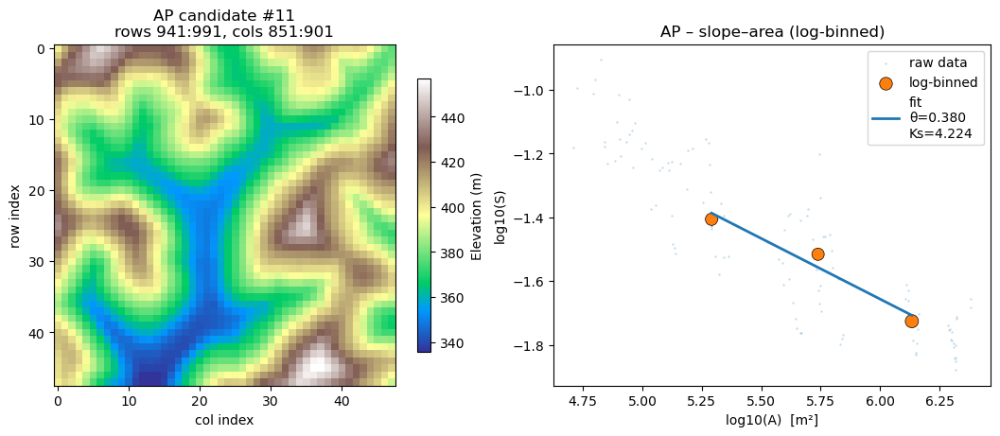


AP – candidate #12   (RMS = 0.098951)
Tile: rows 241:291, cols 751:801   (1440 m × 1440 m)

Results:
  Outlets: 9   Divides: 109   Valid curvatures: 103
  Median D: 9.58e-03 m²/yr  (IQR 6.5e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.74  (Taylor   5.50)
  Ks (m):  4.771  (Taylor  4.400)
  θ      :  0.366  (Taylor  0.370)

Individual errors:
  Curvature:   -4.4%   Ks:   +8.4%   θ:   -1.2%
  3-term RMS error: 0.095928


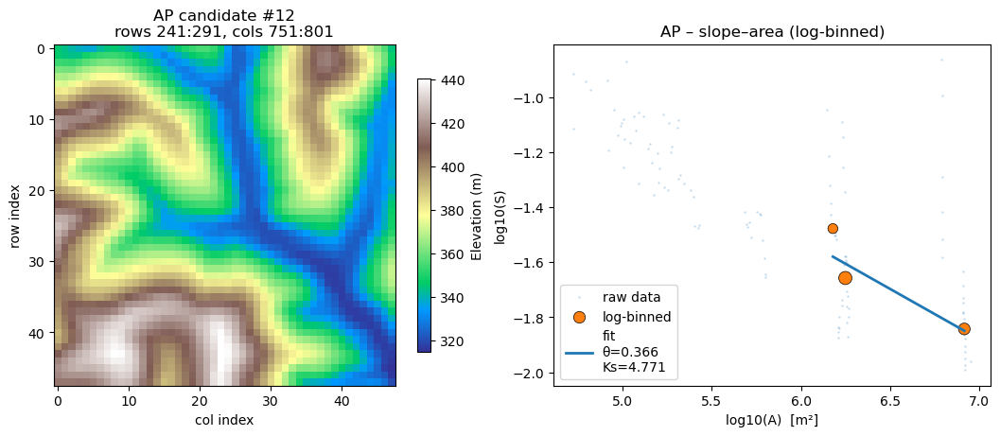


AP – candidate #13   (RMS = 0.101553)
Tile: rows 761:811, cols 991:1041   (1440 m × 1440 m)

Results:
  Outlets: 12   Divides: 52   Valid curvatures: 49
  Median D: 1.01e-02 m²/yr  (IQR 6.4e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.46  (Taylor   5.50)
  Ks (m):  4.824  (Taylor  4.400)
  θ      :  0.375  (Taylor  0.370)

Individual errors:
  Curvature:   +0.8%   Ks:   +9.6%   θ:   +1.4%
  3-term RMS error: 0.097692


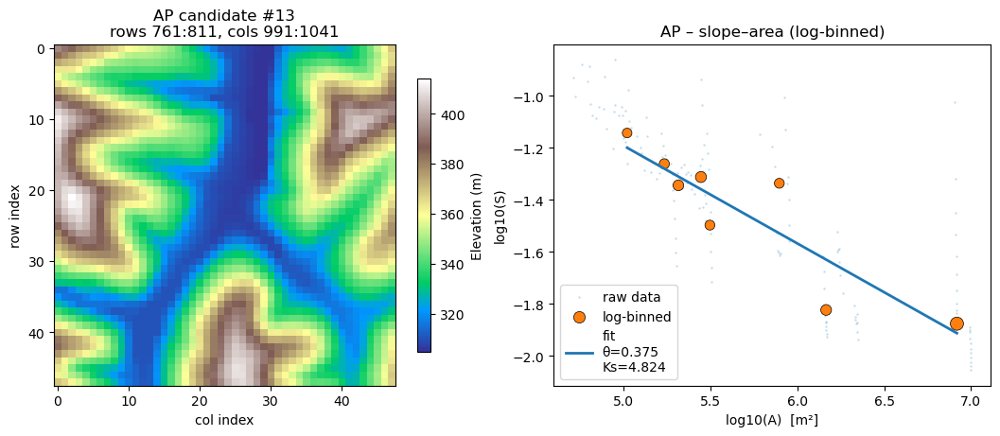


AP – candidate #14   (RMS = 0.104087)
Tile: rows 1061:1111, cols 1411:1461   (1440 m × 1440 m)

Results:
  Outlets: 17   Divides: 226   Valid curvatures: 213
  Median D: 1.01e-02 m²/yr  (IQR 6.6e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.44  (Taylor   5.50)
  Ks (m):  4.665  (Taylor  4.400)
  θ      :  0.356  (Taylor  0.370)

Individual errors:
  Curvature:   +1.0%   Ks:   +6.0%   θ:   -3.8%
  3-term RMS error: 0.071840


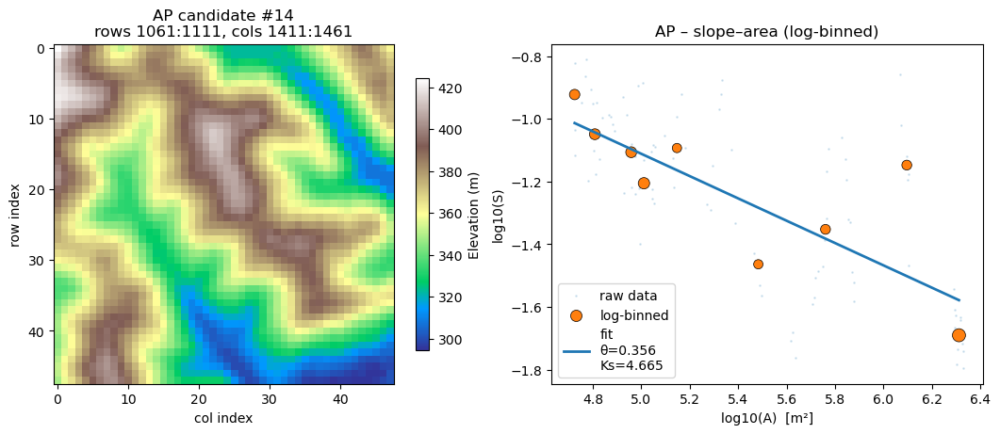


AP – candidate #15   (RMS = 0.105480)
Tile: rows 381:431, cols 691:741   (1440 m × 1440 m)

Results:
  Outlets: 10   Divides: 107   Valid curvatures: 99
  Median D: 9.81e-03 m²/yr  (IQR 7.1e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.60  (Taylor   5.50)
  Ks (m):  3.990  (Taylor  4.400)
  θ      :  0.362  (Taylor  0.370)

Individual errors:
  Curvature:   -1.9%   Ks:   -9.3%   θ:   -2.0%
  3-term RMS error: 0.097339


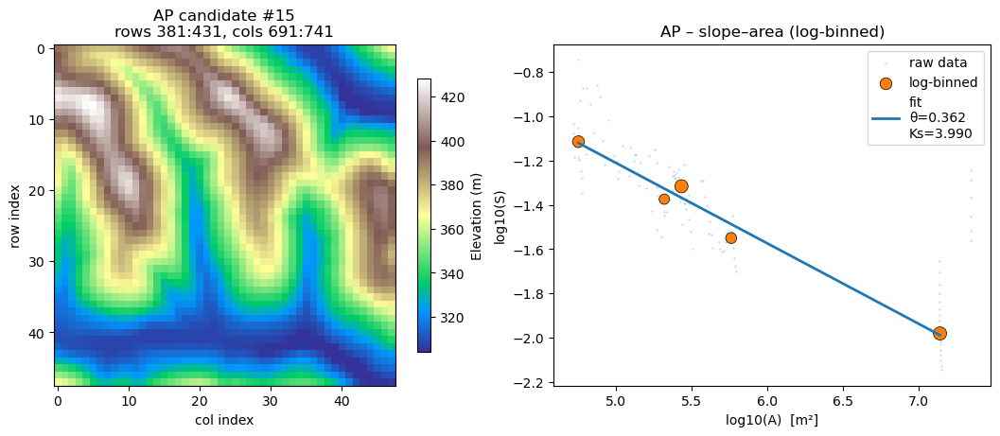


AP – candidate #16   (RMS = 0.106249)
Tile: rows 601:651, cols 841:891   (1440 m × 1440 m)

Results:
  Outlets: 7   Divides: 68   Valid curvatures: 67
  Median D: 1.07e-02 m²/yr  (IQR 6.8e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.12  (Taylor   5.50)
  Ks (m):  4.737  (Taylor  4.400)
  θ      :  0.374  (Taylor  0.370)

Individual errors:
  Curvature:   +6.9%   Ks:   +7.7%   θ:   +1.2%
  3-term RMS error: 0.103507


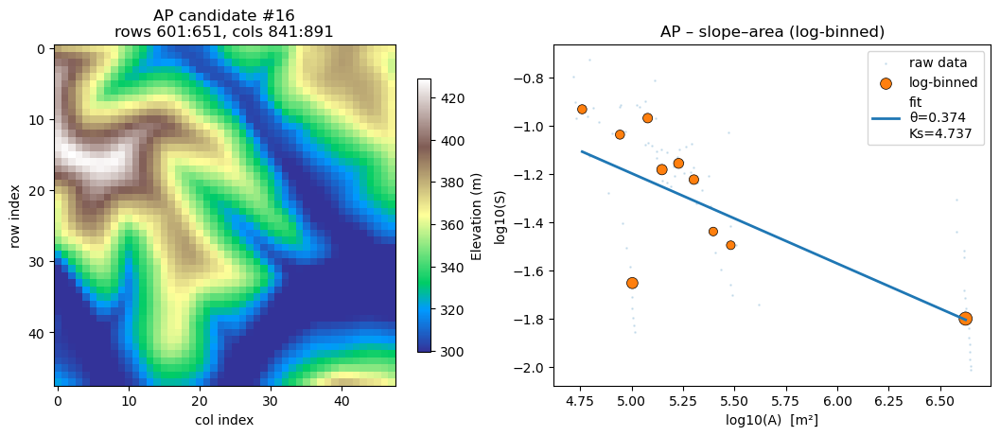


AP – candidate #17   (RMS = 0.107806)
Tile: rows 601:651, cols 781:831   (1440 m × 1440 m)

Results:
  Outlets: 11   Divides: 145   Valid curvatures: 143
  Median D: 9.84e-03 m²/yr  (IQR 7.0e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.59  (Taylor   5.50)
  Ks (m):  4.426  (Taylor  4.400)
  θ      :  0.352  (Taylor  0.370)

Individual errors:
  Curvature:   -1.7%   Ks:   +0.6%   θ:   -4.8%
  3-term RMS error: 0.050734


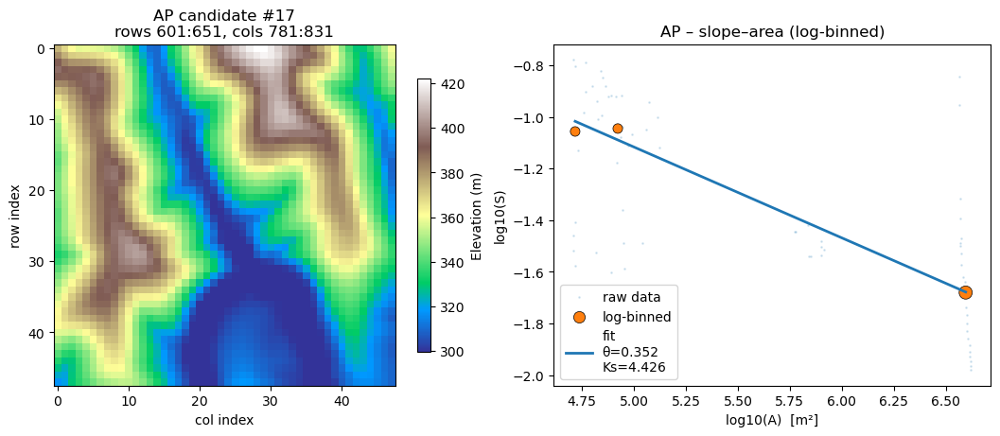


AP – candidate #18   (RMS = 0.107984)
Tile: rows 391:441, cols 691:741   (1440 m × 1440 m)

Results:
  Outlets: 11   Divides: 126   Valid curvatures: 117
  Median D: 9.57e-03 m²/yr  (IQR 7.2e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.75  (Taylor   5.50)
  Ks (m):  4.826  (Taylor  4.400)
  θ      :  0.373  (Taylor  0.370)

Individual errors:
  Curvature:   -4.5%   Ks:   +9.7%   θ:   +0.8%
  3-term RMS error: 0.106915


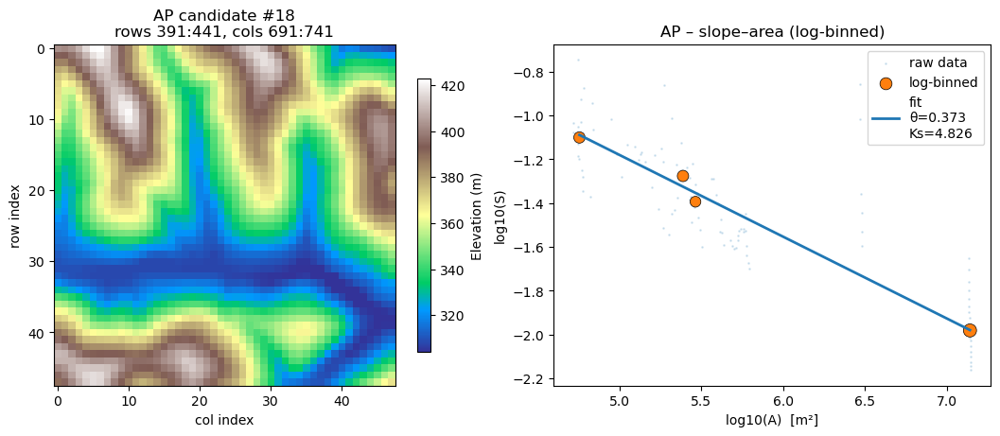


AP – candidate #19   (RMS = 0.108366)
Tile: rows 391:441, cols 601:651   (1440 m × 1440 m)

Results:
  Outlets: 11   Divides: 112   Valid curvatures: 105
  Median D: 9.30e-03 m²/yr  (IQR 6.3e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.91  (Taylor   5.50)
  Ks (m):  4.226  (Taylor  4.400)
  θ      :  0.359  (Taylor  0.370)

Individual errors:
  Curvature:   -7.5%   Ks:   -3.9%   θ:   -3.0%
  3-term RMS error: 0.090109


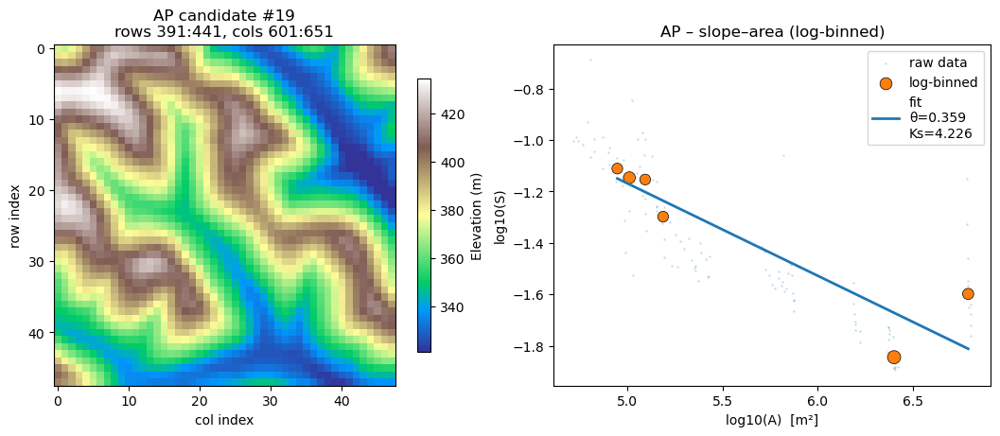


AP – candidate #20   (RMS = 0.115774)
Tile: rows 711:761, cols 631:681   (1440 m × 1440 m)

Results:
  Outlets: 9   Divides: 84   Valid curvatures: 82
  Median D: 9.27e-03 m²/yr  (IQR 7.0e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.93  (Taylor   5.50)
  Ks (m):  4.029  (Taylor  4.400)
  θ      :  0.368  (Taylor  0.370)

Individual errors:
  Curvature:   -7.8%   Ks:   -8.4%   θ:   -0.6%
  3-term RMS error: 0.115187


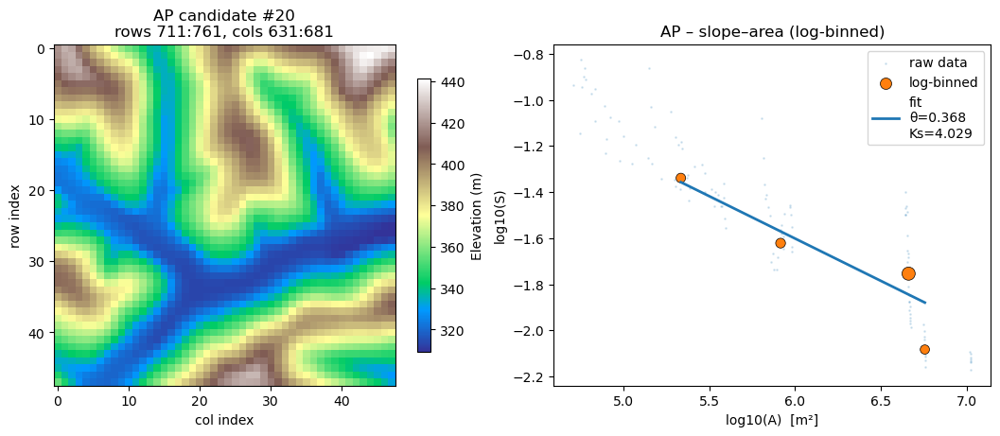


AP – candidate #21   (RMS = 0.118569)
Tile: rows 1161:1211, cols 1041:1091   (1440 m × 1440 m)

Results:
  Outlets: 12   Divides: 197   Valid curvatures: 184
  Median D: 9.11e-03 m²/yr  (IQR 6.1e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.04  (Taylor   5.50)
  Ks (m):  4.451  (Taylor  4.400)
  θ      :  0.359  (Taylor  0.370)

Individual errors:
  Curvature:   -9.8%   Ks:   +1.1%   θ:   -2.9%
  3-term RMS error: 0.103205


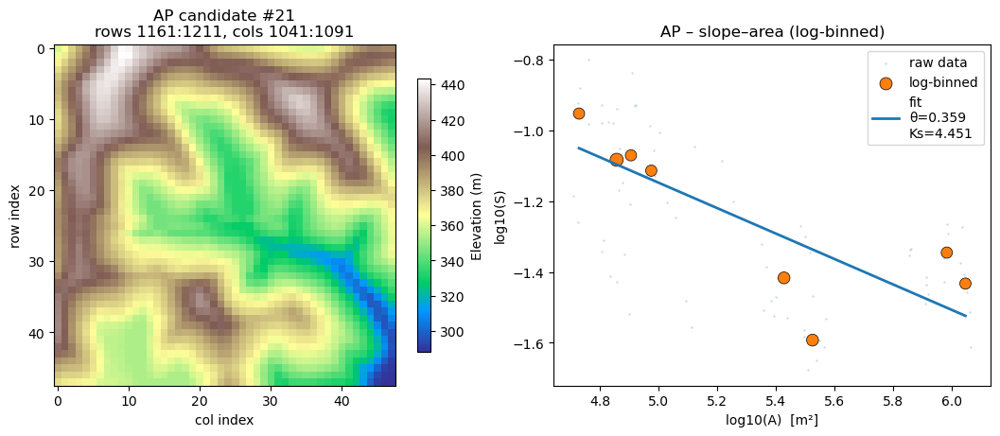


AP – candidate #22   (RMS = 0.119039)
Tile: rows 721:771, cols 1001:1051   (1440 m × 1440 m)

Results:
  Outlets: 9   Divides: 79   Valid curvatures: 72
  Median D: 9.06e-03 m²/yr  (IQR 7.1e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.07  (Taylor   5.50)
  Ks (m):  4.226  (Taylor  4.400)
  θ      :  0.363  (Taylor  0.370)

Individual errors:
  Curvature:  -10.4%   Ks:   -4.0%   θ:   -1.9%
  3-term RMS error: 0.113019


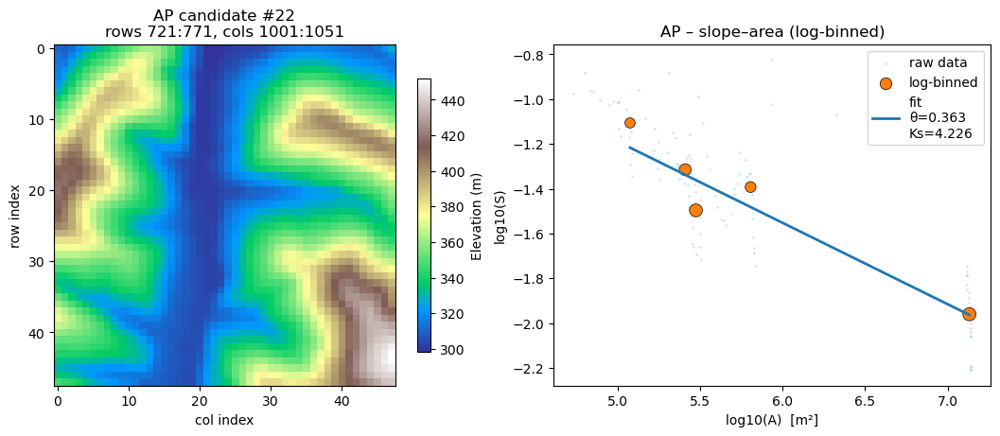


AP – candidate #23   (RMS = 0.119059)
Tile: rows 1121:1171, cols 1251:1301   (1440 m × 1440 m)

Results:
  Outlets: 10   Divides: 86   Valid curvatures: 82
  Median D: 1.09e-02 m²/yr  (IQR 8.2e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.06  (Taylor   5.50)
  Ks (m):  4.787  (Taylor  4.400)
  θ      :  0.368  (Taylor  0.370)

Individual errors:
  Curvature:   +7.9%   Ks:   +8.8%   θ:   -0.5%
  3-term RMS error: 0.118620


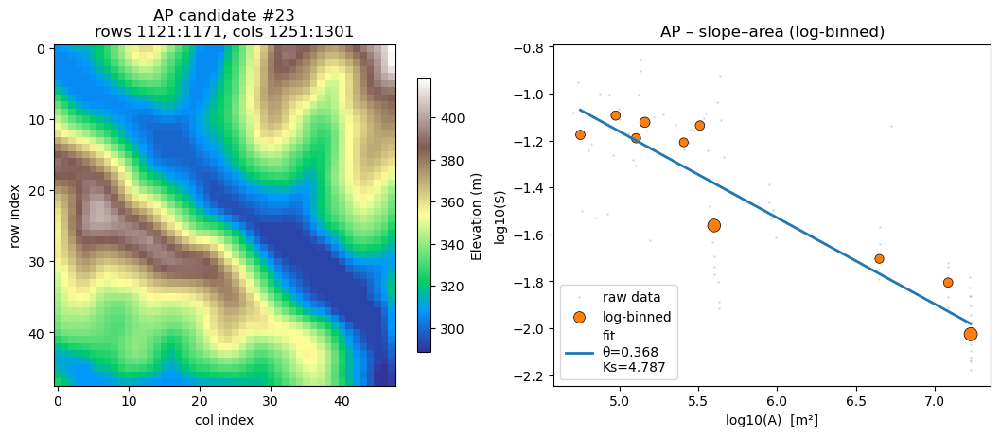


AP – candidate #24   (RMS = 0.119235)
Tile: rows 811:861, cols 941:991   (1440 m × 1440 m)

Results:
  Outlets: 11   Divides: 134   Valid curvatures: 129
  Median D: 9.37e-03 m²/yr  (IQR 7.1e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.87  (Taylor   5.50)
  Ks (m):  4.173  (Taylor  4.400)
  θ      :  0.356  (Taylor  0.370)

Individual errors:
  Curvature:   -6.7%   Ks:   -5.2%   θ:   -3.8%
  3-term RMS error: 0.092575


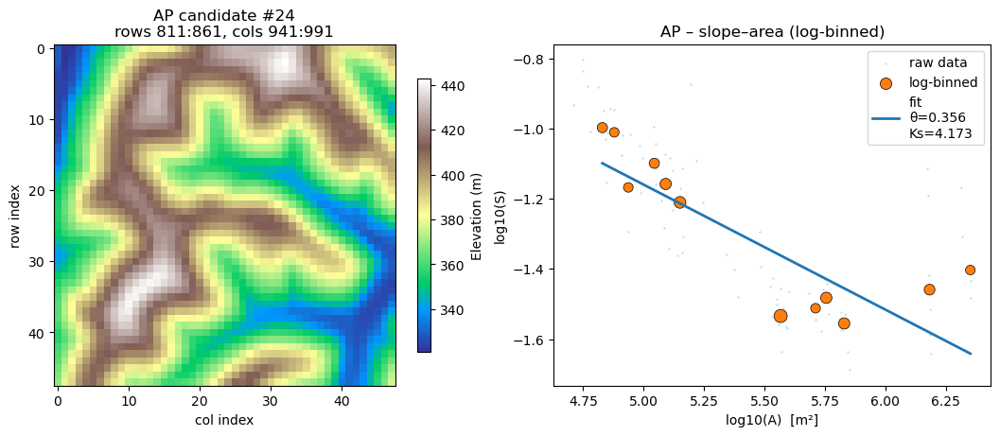


AP – candidate #25   (RMS = 0.121105)
Tile: rows 671:721, cols 1121:1171   (1440 m × 1440 m)

Results:
  Outlets: 12   Divides: 103   Valid curvatures: 93
  Median D: 9.08e-03 m²/yr  (IQR 5.9e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.06  (Taylor   5.50)
  Ks (m):  4.241  (Taylor  4.400)
  θ      :  0.379  (Taylor  0.370)

Individual errors:
  Curvature:  -10.1%   Ks:   -3.6%   θ:   +2.5%
  3-term RMS error: 0.110137


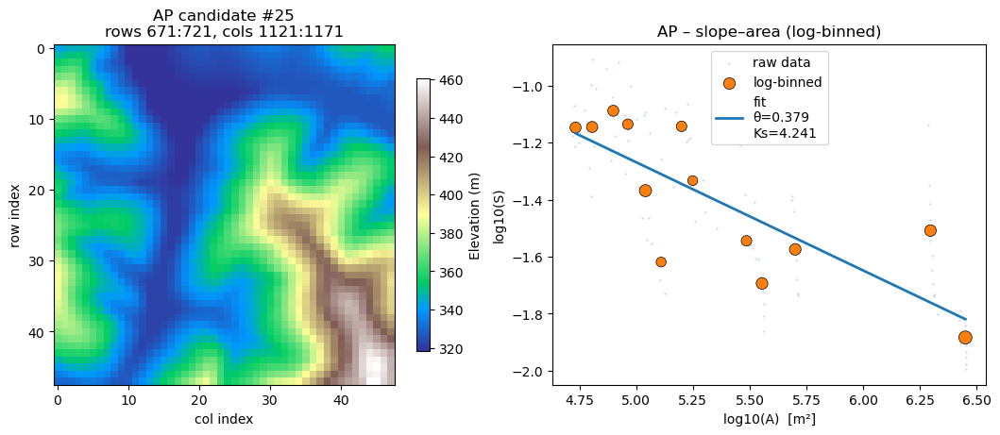


AP – candidate #26   (RMS = 0.125013)
Tile: rows 291:341, cols 691:741   (1440 m × 1440 m)

Results:
  Outlets: 7   Divides: 77   Valid curvatures: 73
  Median D: 9.79e-03 m²/yr  (IQR 6.6e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.62  (Taylor   5.50)
  Ks (m):  3.863  (Taylor  4.400)
  θ      :  0.373  (Taylor  0.370)

Individual errors:
  Curvature:   -2.2%   Ks:  -12.2%   θ:   +0.7%
  3-term RMS error: 0.124123


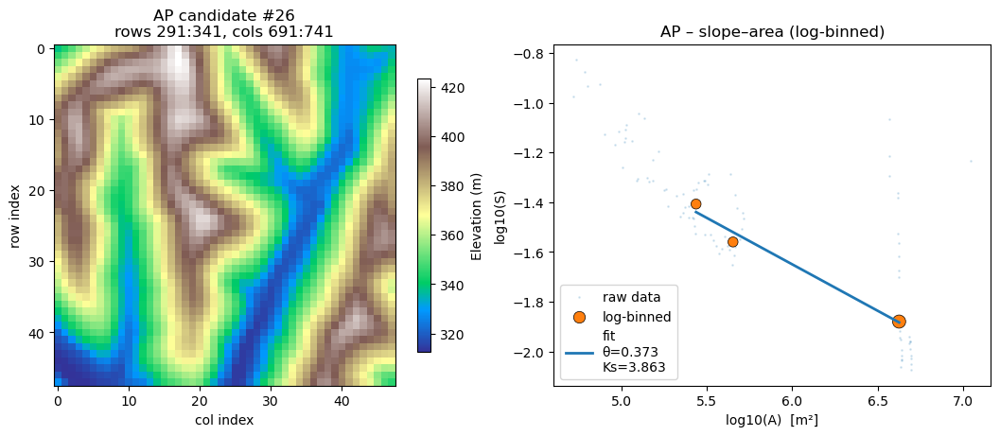


AP – candidate #27   (RMS = 0.129602)
Tile: rows 701:751, cols 911:961   (1440 m × 1440 m)

Results:
  Outlets: 13   Divides: 138   Valid curvatures: 129
  Median D: 1.02e-02 m²/yr  (IQR 6.7e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.39  (Taylor   5.50)
  Ks (m):  4.333  (Taylor  4.400)
  θ      :  0.349  (Taylor  0.370)

Individual errors:
  Curvature:   +1.9%   Ks:   -1.5%   θ:   -5.7%
  3-term RMS error: 0.062012


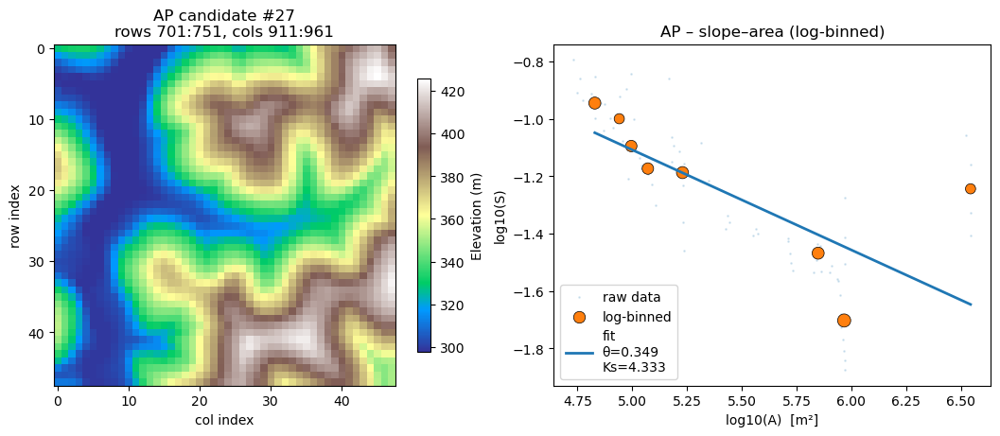


AP – candidate #28   (RMS = 0.129906)
Tile: rows 871:921, cols 831:881   (1440 m × 1440 m)

Results:
  Outlets: 13   Divides: 145   Valid curvatures: 143
  Median D: 9.54e-03 m²/yr  (IQR 6.4e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.77  (Taylor   5.50)
  Ks (m):  3.891  (Taylor  4.400)
  θ      :  0.376  (Taylor  0.370)

Individual errors:
  Curvature:   -4.9%   Ks:  -11.6%   θ:   +1.5%
  3-term RMS error: 0.126262


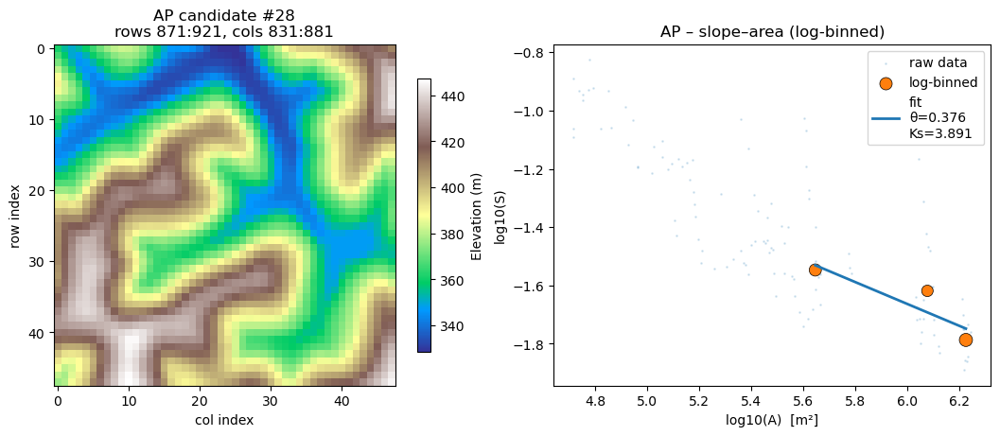


AP – candidate #29   (RMS = 0.133489)
Tile: rows 591:641, cols 1221:1271   (1440 m × 1440 m)

Results:
  Outlets: 10   Divides: 119   Valid curvatures: 116
  Median D: 1.05e-02 m²/yr  (IQR 7.1e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.25  (Taylor   5.50)
  Ks (m):  4.348  (Taylor  4.400)
  θ      :  0.391  (Taylor  0.370)

Individual errors:
  Curvature:   +4.5%   Ks:   -1.2%   θ:   +5.6%
  3-term RMS error: 0.072855


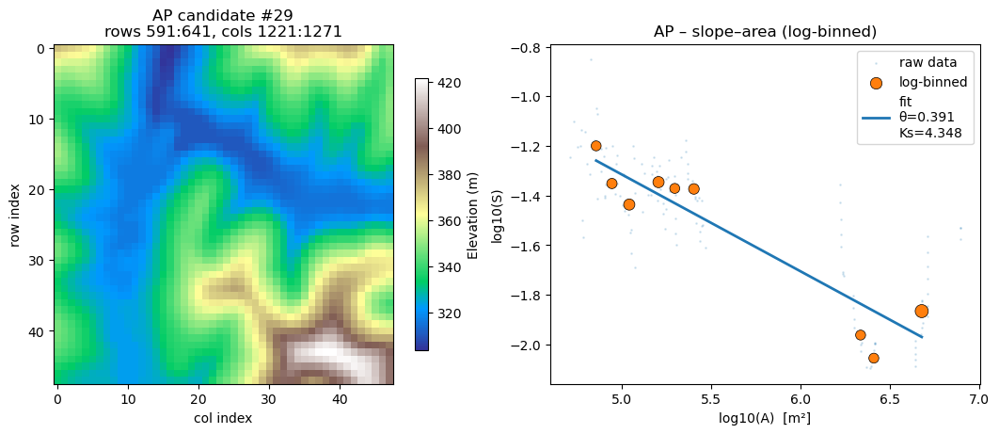


AP – candidate #30   (RMS = 0.134109)
Tile: rows 681:731, cols 1001:1051   (1440 m × 1440 m)

Results:
  Outlets: 11   Divides: 74   Valid curvatures: 73
  Median D: 1.00e-02 m²/yr  (IQR 6.5e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.50  (Taylor   5.50)
  Ks (m):  4.982  (Taylor  4.400)
  θ      :  0.374  (Taylor  0.370)

Individual errors:
  Curvature:   +0.0%   Ks:  +13.2%   θ:   +1.0%
  3-term RMS error: 0.132559


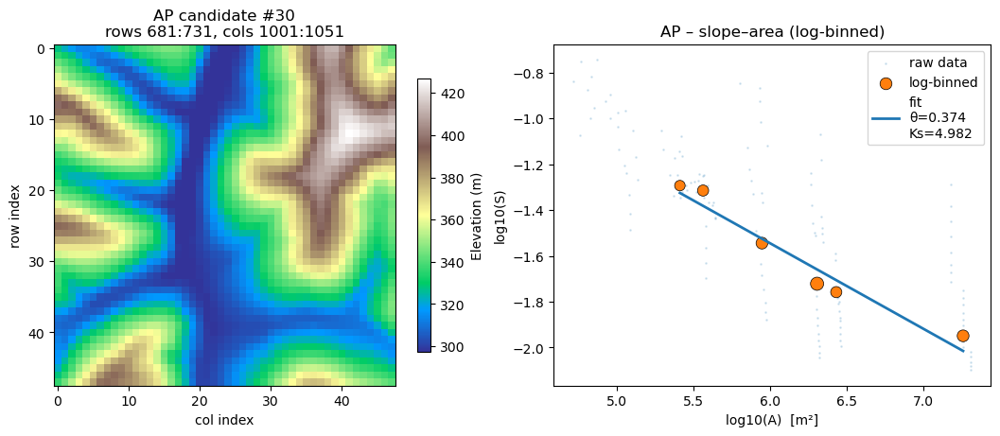


TILE ANALYSIS COMPLETE

Analysed successfully: 60/60 tiles


In [41]:
##### ── make sure this is imported / in scope somewhere above ───────────────
# from your_module import slope_area_regression_binned

# ════════════════════════════════════════════════════════════════════════
#  ANALYSIS OF SELECTED TILES  –  TOP-3 PER LANDSCAPE
# ════════════════════════════════════════════════════════════════════════
print("="*80)
print("ANALYSIS OF SELECTED TILES (TOP-3 PER LANDSCAPE)")
print("="*80)

results = {}

for tag in DATA:
    # -------------------------------------------------------------------
    if tag not in BEST_TILE:
        print(f"\n⚠️  Skipping {tag} – no tiles recorded")
        continue

    # --- load the *full* landscape (ignore any stored crop) -------------
    saved_crop          = DATA[tag]["crop"]   # remember single-best crop
    DATA[tag]["crop"]   = None                # disable cropping
    elev_full, area_full, fd_full, cfg = load_site(tag)
    DATA[tag]["crop"]   = saved_crop          # restore

    dx, U      = cfg["dx"], cfg["U"]
    ref        = TAYLOR_REF[tag]

    # -------------------------------------------------------------------
    for rank, (best_err, (rs, cs)) in enumerate(BEST_TILE[tag], 1):
        print(f"\n{'='*60}")
        print(f"{tag} – candidate #{rank}   (RMS = {best_err:.6f})")
        print(f"{'='*60}")

        # ---- crop the full grids to this candidate ---------------------
        elev, area, fd = crop((elev_full, area_full, fd_full),
                              extent_indexes=(rs.start, rs.stop, cs.start, cs.stop))
        ny, nx = elev._griddata.shape
        print(f"Tile: rows {rs.start}:{rs.stop}, cols {cs.start}:{cs.stop}   "
              f"({ny*dx} m × {nx*dx} m)")

        try:
            # —— curvature on first-order divides ————————————————
            curv_vals, divides, labels, outs = ta.extract_hilltop_curvature_first_order(
                elev, area, fd, ref["Acrit"], stencil=9)

            # —— diffusivity stats ————————————————————————————————
            D_stats, _      = ta.diffusivity_stats_new(curv_vals, U)
            D_med, D_iqr, _ = D_stats

            # —— channel steepness & concavity — LOG-BINNED regression —
            Ks, theta, sa_dbg = slope_area_regression_binned(
                elev, area, fd,
                min_area=ref["Acrit"],
                vertical_interval=10,   # keep your convention
                nbins=24,               # tweak if you prefer
                min_per_bin=10,
                agg="median",
                require_weighted=True,
                relax_if_sparse=True
            )

            # —— store results ———————————————————————————————
            results[(tag, rank)] = dict(
                curvature=curv_vals, divides=divides, outlets=outs,
                Ks=Ks, theta=theta, D_stats=D_stats,
                elev=elev, area=area, fd=fd,
                sa_debug=sa_dbg,         # raw + binned arrays for plotting
                success=True
            )

            # —— reporting ————————————————————————————————
            # Positive magnitude for hilltop curvature (median hilltops are negative):
            med_curv_mag   = -np.median(curv_vals)      # > 0 for convex hilltops
            ks_target      = ref["U"] / ref["K"]
            theta_target   = ref["theta"]
            curv_tbl       = med_curv_mag*1e3           # ×10⁻³ m⁻¹ (positive)
            target_tbl     = -ref["curv"]*1e3           # if ref["curv"] is negative

            print("\nResults:")
            print(f"  Outlets: {len(outs)}   Divides: {len(divides)}   "
                  f"Valid curvatures: {len(curv_vals)}")
            print(f"  Median D: {D_med:.2e} m²/yr  "
                  f"(IQR {D_iqr[0]:.1e}–{D_iqr[1]:.1e})")

            print("\nComparison with Taylor et al. (2006):")
            print(f"  Curvature |∇²z| (10⁻³ m⁻¹): {curv_tbl:6.2f}  "
                  f"(Taylor {target_tbl:6.2f})")
            print(f"  Ks (m): {Ks:6.3f}  (Taylor {ks_target:6.3f})")
            print(f"  θ      : {theta:6.3f}  (Taylor {theta_target:6.3f})")

            # —— error metrics ——————————————————————————————
            # Note: this preserves your earlier convention of comparing the
            # positive magnitude med_curv_mag to ref["curv"] (typically negative).
            curv_err  = 100*(med_curv_mag - ref["curv"]) / abs(ref["curv"])
            ks_err    = 100*(Ks - ks_target) / ks_target
            theta_err = 100*(theta - theta_target) / theta_target
            rms_err   = np.sqrt((curv_err/100)**2 +
                                 (ks_err/100)**2 +
                                 (theta_err/100)**2)

            print("\nIndividual errors:")
            print(f"  Curvature: {curv_err:+6.1f}%   "
                  f"Ks: {ks_err:+6.1f}%   θ: {theta_err:+6.1f}%")
            print(f"  3-term RMS error: {rms_err:.6f}")

        except Exception as e:
            print(f"❌  Analysis failed: {e}")
            results[(tag, rank)] = dict(success=False, error=str(e))
            continue

        # ── quick elevation + slope–area plots for each candidate ───────
        import matplotlib.pyplot as plt
        fig, (ax_e, ax_sa) = plt.subplots(1, 2, figsize=(11, 4.5),
                                          constrained_layout=True)

        # Elevation
        im = ax_e.imshow(elev._griddata, cmap="terrain", origin="upper")
        ax_e.set_title(f"{tag} candidate #{rank}\nrows {rs.start}:{rs.stop}, cols {cs.start}:{cs.stop}")
        ax_e.set_xlabel("col index"); ax_e.set_ylabel("row index")
        cbar = plt.colorbar(im, ax=ax_e, shrink=0.8, label="Elevation (m)")

        # Slope–Area: raw + binned + fit
        logA_raw, logS_raw = sa_dbg["logA"], sa_dbg["logS"]
        ax_sa.scatter(logA_raw, logS_raw, s=1, alpha=0.15, label="raw data")

        bA, bS, bN = sa_dbg["bin_logA"], sa_dbg["bin_logS"], sa_dbg["bin_counts"]
        sizes = 20 + 80 * (bN / np.max(bN)) if np.max(bN) > 0 else 40
        ax_sa.scatter(bA, bS, s=sizes, edgecolor="k", linewidths=0.5, label="log-binned")

        x_fit = np.linspace(np.min(bA), np.max(bA), 2)
        ax_sa.plot(x_fit, np.log10(Ks) - theta * x_fit, lw=2,
                   label=f"fit\nθ={theta:.3f}\nKs={Ks:.3f}")

        ax_sa.set_xlabel("log10(A)  [m²]")
        ax_sa.set_ylabel("log10(S)")
        ax_sa.set_title(f"{tag} – slope–area (log-binned)")
        ax_sa.legend(loc="best", frameon=True)

        plt.show()

# ────────────────────────────────────────────────────────────────────────

# ─── summary ─────────────────────────────────────────────────────────────
print("\n" + "="*80)
print("TILE ANALYSIS COMPLETE")
print("="*80)

success_count = sum(1 for v in results.values() if v.get('success'))
print(f"\nAnalysed successfully: {success_count}/{len(results)} tiles")


In [13]:
# ────────────────────────────────────────────────────────────────
#  UTM extent for the hand-picked tiles
#  (GM rows 2041-2191 / cols 901-1051;  AP rows 291-341 / cols 691-741)
# ────────────────────────────────────────────────────────────────
import rasterio

TILES = {
    "GM": dict(rows=(1741, 2041), cols=(961, 1261)),   # 150 × 150 px (@10 m) 1891:2041, cols 931:1081
    "AP": dict(rows=( 321,  371), cols=(751,  801)),   }

def tile_bounds(transform, r0, r1, c0, c1):
    """
    Convert pixel-space tile limits (Python slices) to UTM coordinates.

    Parameters
    ----------
    transform : rasterio.transform.Affine
        Affine mapping from pixel-space to map-space.
    r0, r1 : int
        Slice start / stop rows   (NOTE: r1 is exclusive, just like Python slices).
    c0, c1 : int
        Slice start / stop cols   (c1 exclusive).

    Returns
    -------
    (west, east, south, north)  in metres
    """
    west  = transform.c + c0 * transform.a
    east  = transform.c + c1 * transform.a
    north = transform.f + r0 * transform.e     # transform.e is usually negative
    south = transform.f + r1 * transform.e
    return west, east, south, north


print("="*78)
print("UTM BOUNDING BOXES FOR SELECTED 1.5 km × 1.5 km TILES")
print("="*78)
print(f"{'Dataset':<6} {'West (mE)':>13} {'East (mE)':>13} "
      f"{'South (mN)':>13} {'North (mN)':>13}")

for tag, idx in TILES.items():
    path = DATA[tag]["elev"]          # path to the DEM you’re already using
    with rasterio.open(path) as src:
        tr = src.transform
    w, e, s, n = tile_bounds(tr,
                             idx["rows"][0], idx["rows"][1],
                             idx["cols"][0], idx["cols"][1])

    print(f"{tag:<6} {w:13.0f} {e:13.0f} {s:13.0f} {n:13.0f}")

print("\nCopy-and-paste those four numbers into your LiDAR-download or "
      "gdal_translate command to crop the raw LiDAR tiles.")


UTM BOUNDING BOXES FOR SELECTED 1.5 km × 1.5 km TILES
Dataset     West (mE)     East (mE)    South (mN)    North (mN)
GM            699591        702591       3980051       3983051
AP            560313        561813       4422980       4424480

Copy-and-paste those four numbers into your LiDAR-download or gdal_translate command to crop the raw LiDAR tiles.


In [27]:
# ─────────────────────────────────────────────────────────────────
#  LOG BINNED APPROACH
#  Curvature, log-binned Ks/θ, diffusivity, Taylor comparison
#  (printing style identical to 30 m workflow)
# ─────────────────────────────────────────────────────────────────
import numpy as np
from pathlib import Path
from TopoAnalysis import dem as d
import topo_analysis as ta

#  Assumes:
#    • diffusivity_stats_new is defined above
#    • TAYLOR_REF and DATA dictionaries are in memory

# ── log-binned slope–area regression (paste if not already imported) ───
def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10, nbins=24, min_per_bin=10,
    agg="median", require_weighted=True, relax_if_sparse=True
):
    """Return (Ks, theta, debug) from a log-binned fit of log10 S vs log10 A."""
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")
    bin_edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            left, right = bin_edges[i], bin_edges[i+1]
            idx = (logA >= left) & (logA < right) if i < nbins - 1 else (logA >= left) & (logA <= right)
            c = int(np.count_nonzero(idx))
            if c < min_required: continue
            a_val = np.median(logA[idx]) if agg == "median" else np.mean(logA[idx])
            s_val = np.median(logS[idx]) if agg == "median" else np.mean(logS[idx])
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return outA, outS, outN

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and len(bA) < 3:
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if len(bA) >= 3: break
    if len(bA) < 3:
        raise ValueError("Too few populated bins for regression.")

    bA = np.asarray(bA); bS = np.asarray(bS); w = np.asarray(w, float)
    # Weighted least squares on binned aggregates
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den == 0: raise RuntimeError("Zero variance in binned log10(A).")
    b1 = num / den
    b0 = wy - b1 * wx
    Ks = 10**b0
    theta = -b1
    dbg = dict(logA=logA, logS=logS, bin_logA=bA, bin_logS=bS, bin_counts=w, bin_edges=bin_edges)
    return Ks, theta, dbg

# ── inputs ──────────────────────────────────────────────────────────────
tile_dir = Path("data/best_fit_tiles/best_tile_fit_3km/best_tile_fit_3km_extracted_from_full_grids/")
tiles = {
    "AP": dict(prefix="log_binned_results/AP_1m_best_fit", theta=0.37, Acrit=5.04e4),
    "GM": dict(prefix="GM_1m_best_fit_3km",                theta=0.35, Acrit=1.0e4),
}

line = "-" * 60
for tag, cfg in tiles.items():
    print(f"Analyzing selected tile for {tag}\n{line}")

    stem   = tile_dir / cfg["prefix"]
    # filled acts as elevation for 1 m; no separate _elevation required
    filled = d.FilledElevation.load(str(stem) + "_filled")
    area   = d.Area.load(           str(stem) + "_area")
    fd     = d.FlowDirectionD8.load(str(stem) + "_fd")

    # 1) Hilltop curvature (positive magnitudes in m⁻¹ from TA helper)
    curv_vals_px, divides, labels, outs = ta.extract_hilltop_curvature_first_order(
        filled, area, fd, cfg["Acrit"], stencil=9
    )
    med_curv_mag = np.median(curv_vals_px)

    # 2) Ks & θ from LOG-BINNED slope–area on the 1 m data
    Ks, theta, _sa_dbg = slope_area_regression_binned(
        elev_obj=filled, area_obj=area, fd_obj=fd,
        min_area=cfg["Acrit"],
        vertical_interval=10,   # keep consistent smoothing
        nbins=24, min_per_bin=10, agg="median",
        require_weighted=True, relax_if_sparse=True
    )

    # 3) Diffusivity stats
    U = DATA[tag]["U"]          # uplift rate (m/yr)
    D_stats, _ = ta.diffusivity_stats_new(curv_vals_px, U)
    D_med, (D_q25, D_q75), _ = D_stats

    # 4) Taylor reference & error metrics
    ref = TAYLOR_REF[tag]
    curv_target = abs(ref["curv"])
    Ks_target   = ref["U"] / ref["K"]

    curv_err  = 100 * (med_curv_mag - curv_target) / curv_target
    ks_err    = 100 * (Ks           - Ks_target)   / Ks_target
    theta_err = 100 * (theta        - ref["theta"]) / ref["theta"]
    rms_err   = np.sqrt((curv_err/100)**2 + (ks_err/100)**2 + (theta_err/100)**2)

    # 5) Report
    unit = "×10⁻³ m⁻¹"
    print("Comparison with Taylor et al. (2006):")
    print(f"  Curvature |∇²z| : {med_curv_mag*1e3:7.2f} {unit}  "
          f"(Taylor: {curv_target*1e3:6.2f} {unit})")
    print(f"  Channel steepness Ks (m):   {Ks:6.3f} "
          f"(Taylor: {Ks_target:6.3f})")
    print(f"  Channel concavity θ:        {theta:6.3f} "
          f"(Taylor: {ref['theta']:6.3f})\n")

    print("Individual errors:")
    print(f"  Curvature error:  {curv_err:+6.1f}%")
    print(f"  Steepness error:  {ks_err:+6.1f}%")
    print(f"  Concavity error:  {theta_err:+6.1f}%")
    print(f"  3-term RMS error: {rms_err:.6f}\n")

    print("Diffusivity statistics:")
    print(f"  Median D: {D_med:6.2e} m²/yr "
          f"(IQR: {D_q25:6.2e} – {D_q75:6.2e})")
    print(line, "\n")


Analyzing selected tile for AP
------------------------------------------------------------
Comparison with Taylor et al. (2006):
  Curvature |∇²z| : 1012.17 ×10⁻³ m⁻¹  (Taylor:   5.50 ×10⁻³ m⁻¹)
  Channel steepness Ks (m):    9.118 (Taylor:  4.400)
  Channel concavity θ:         0.347 (Taylor:  0.370)

Individual errors:
  Curvature error:  +18303.2%
  Steepness error:  +107.2%
  Concavity error:    -6.1%
  3-term RMS error: 183.034925

Diffusivity statistics:
  Median D: 5.43e-05 m²/yr (IQR: 3.19e-05 – 1.03e-04)
------------------------------------------------------------ 

Analyzing selected tile for GM
------------------------------------------------------------
Comparison with Taylor et al. (2006):
  Curvature |∇²z| :  113.72 ×10⁻³ m⁻¹  (Taylor:  11.80 ×10⁻³ m⁻¹)
  Channel steepness Ks (m):    2.597 (Taylor:  1.467)
  Channel concavity θ:         0.310 (Taylor:  0.350)

Individual errors:
  Curvature error:  +863.7%
  Steepness error:   +77.1%
  Concavity error:   -11.3%
  3-term 

In [22]:
# ──────────────────────────────────────────────────────────────────────────
#  LOW-PASS vs. SUBSAMPLED analysis for 1 m best-fit tiles  – final version
#
#  • Assumes you already imported:
#        from TopoAnalysis import dem as d
#        import topo_analysis as ta
#        plus   DATA   and   TAYLOR_REF   dicts in memory
#  • Produces curvature, Ks, θ, and diffusivity for
#        ① Gaussian-blurred 1 m grids (low-pass)
#        ② Block-mean 10 m (GM) / 30 m (AP) grids (subsampled)
# ──────────────────────────────────────────────────────────────────────────
import numpy as np, copy
from pathlib import Path
from scipy.ndimage import gaussian_filter



# ─── helper functions ─────────────────────────────────────────────────────
def fwhm_to_sigma(fwhm_m):
    """Gaussian σ (pixels) from FWHM in metres (native px = 1 m)."""
    return fwhm_m / (2 * np.sqrt(2 * np.log(2)))

def block_mean(arr, k):
    """Down-sample *arr* by integer factor *k* via block averaging."""
    ny, nx = arr.shape
    return (arr[:ny//k*k, :nx//k*k]          # truncate so divisible by k
              .reshape(ny//k, k, nx//k, k)
              .mean(axis=(1, 3)))

def analyse_variant(elev_raw, elev_filled, area, fd, acrit, theta, tag, dx_out):
    """Run curvature → Ks/θ → diffusivity and return summary dict."""
    curv_vals, divides, _, _ = ta.extract_hilltop_curvature_first_order(
        elev_raw, area, fd, acrit, stencil=9)
    curv_med = np.median(curv_vals)

    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_filled, area=area, flow_direction=fd,
        vertical_interval=10, min_area=acrit)
    S = slope_obj._griddata.flatten()
    A = area._griddata.flatten()
    m = (A >= acrit) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    Ks_med = np.median(S[m] * A[m]**theta)

    U = DATA[tag]["U"]
    D_stats, _ = ta.diffusivity_stats_new(curv_vals, U)
    D_med, D_IQR, _ = D_stats

    return dict(curv=curv_med, Ks=Ks_med, theta=theta,
                D_med=D_med, D_IQR=D_IQR, dx=dx_out)

def print_report(tag, label, stats):
    ref = TAYLOR_REF[tag]
    curv_ref, ks_ref, th_ref = abs(ref["curv"]), ref["U"]/ref["K"], ref["theta"]
    errs = [(stats["curv"]  - curv_ref)/curv_ref,
            (stats["Ks"]    - ks_ref)  /ks_ref,
            (stats["theta"] - th_ref)  /th_ref]
    rms = np.sqrt(np.square(errs).sum())
    print(f"\n--- {label:<9} (dx = {stats['dx']:>3} m) ---")
    u = "×10⁻³ m⁻¹"
    print(f"|∇²z|  : {stats['curv']*1e3:7.2f} {u}  "
      f"(Taylor {curv_ref*1e3:6.2f} {u})  "
      f"err {errs[0]*100:+6.1f}%")          
    print(f"Ks     : {stats['Ks']:7.3f}             (Taylor {ks_ref:6.3f})  "
          f"err {errs[1]*100:+6.1f}%")
    print(f"θ      : {stats['theta']:7.3f}             (Taylor {th_ref:6.3f})  "
          f"err {errs[2]*100:+6.1f}%")
    print(f"D_med  : {stats['D_med']:.2e}  (IQR {stats['D_IQR'][0]:.1e}–{stats['D_IQR'][1]:.1e})")
    print(f"RMS (3-term) = {rms:.6f}")

# ─── per-tile configuration ───────────────────────────────────────────────
tile_dir = Path("data/best_fit_tiles/best_tile_fit_3km/best_tile_fit_3km_extracted_from_full_grids/")
tiles = {

    "GM": dict(prefix="GM_1m_best_fit_3km", theta=0.35, Acrit=1.0e4,
               fwhm=10, subs=10),
    "AP": dict(prefix="AP_1m_best_fit", theta=0.37, Acrit=5.04e4,
               fwhm=30, subs=30),
}

# ─── main loop ────────────────────────────────────────────────────────────
for tag, cfg in tiles.items():
    print(f"\n======== {tag}  (filter {cfg['fwhm']} m  |  subs {cfg['subs']} m) ========")

    # load native 1 m rasters -------------------------------------------------
    stem = tile_dir / cfg["prefix"]
    print(stem)
    elev1  = d.Elevation.load(str(stem) + "_elevation")
    fill1  = d.FilledElevation.load(str(stem) + "_filled")
    area1  = d.Area.load(str(stem) + "_area")
    fd1    = d.FlowDirectionD8.load(str(stem) + "_fd")   # your saved flow grid
    z_native = elev1._griddata.copy()

    # LOW-PASS branch ---------------------------------------------------------
    z_lp = gaussian_filter(z_native, sigma=fwhm_to_sigma(cfg["fwhm"]),
                           mode="nearest")
    elev_lp = copy.deepcopy(elev1);  elev_lp._griddata = z_lp
    fill_lp = copy.deepcopy(fill1);  fill_lp._griddata = z_lp

    stats_lp = analyse_variant(elev_lp, fill_lp, area1, fd1,
                               cfg["Acrit"], cfg["theta"], tag, dx_out=1)
    print_report(tag, "low-pass", stats_lp)

    # SUBSAMPLED branch -------------------------------------------------------
    k = cfg["subs"]
    z_sub = block_mean(z_native, k)
    a_sub = block_mean(area1._griddata, k)

    elev_sub = copy.deepcopy(elev1)
    elev_sub._griddata = z_sub
    elev_sub._georef_info.dx = elev_sub._georef_info.dy = k
    elev_sub._georef_info.nrows = elev_sub._georef_info.ny  = z_sub.shape[0]
    elev_sub._georef_info.ncols = elev_sub._georef_info.nx  = z_sub.shape[1]

    fill_sub = copy.deepcopy(fill1)
    fill_sub._griddata = z_sub
    fill_sub._georef_info = elev_sub._georef_info

    # rebuild flow direction and contributing area just like process_dem()
    fd_sub   = d.FlowDirectionD8(flooded_dem=fill_sub)
    area_sub = d.Area(flow_direction=fd_sub)

    stats_sub = analyse_variant(elev_sub, fill_sub, area_sub, fd_sub,
                                cfg["Acrit"], cfg["theta"], tag, dx_out=k)
    print_report(tag, "subsample", stats_sub)



======== GM  (filter 10 m  |  subs 10 m) ========
data/best_fit_tiles/best_tile_fit_3km/best_tile_fit_3km_extracted_from_full_grids/GM_1m_best_fit_3km

--- low-pass  (dx =   1 m) ---
|∇²z|  :    7.86 ×10⁻³ m⁻¹  (Taylor  11.80 ×10⁻³ m⁻¹)  err  -33.4%
Ks     :   4.122             (Taylor  1.467)  err +181.0%
θ      :   0.350             (Taylor  0.350)  err   +0.0%
D_med  : 1.87e-02  (IQR 1.2e-02–3.5e-02)
RMS (3-term) = 1.840544

--- subsample (dx =  10 m) ---
|∇²z|  :   12.13 ×10⁻³ m⁻¹  (Taylor  11.80 ×10⁻³ m⁻¹)  err   +2.8%
Ks     :   3.857             (Taylor  1.467)  err +162.9%
θ      :   0.350             (Taylor  0.350)  err   +0.0%
D_med  : 1.21e-02  (IQR 8.8e-03–1.8e-02)
RMS (3-term) = 1.629361

======== AP  (filter 30 m  |  subs 30 m) ========
data/best_fit_tiles/best_tile_fit_3km/best_tile_fit_3km_extracted_from_full_grids/AP_1m_best_fit

--- low-pass  (dx =   1 m) ---
|∇²z|  :   12.30 ×10⁻³ m⁻¹  (Taylor   5.50 ×10⁻³ m⁻¹)  err +123.6%
Ks     :  13.149             (Taylor  4.4

In [32]:
# ──────────────────────────────────────────────────────────────────────────
# LOG BINNED VERSION 
#    LOW-PASS vs. SUBSAMPLED analysis for 1 m best-fit tiles  – log-binned Ks/θ
#
#  • Requires:
#        from TopoAnalysis import dem as d
#        import topo_analysis as ta
#        plus   DATA   and   TAYLOR_REF   dicts in memory
#  • Computes curvature, Ks, θ, and diffusivity for:
#        ① Gaussian-blurred 1 m grids (low-pass)
#        ② Block-mean 10 m (GM) / 30 m (AP) grids (subsampled)
#  • Uses log-binned slope–area regression for Ks and θ
# ──────────────────────────────────────────────────────────────────────────
import numpy as np, copy
from pathlib import Path
from scipy.ndimage import gaussian_filter
from TopoAnalysis import dem as d

# ─── log-binned slope–area regression ────────────────────────────────────
def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10, nbins=24, min_per_bin=10,
    agg="median", require_weighted=True, relax_if_sparse=True
):
    """
    Fit log10(S) vs log10(A) using log-binned aggregates to obtain Ks and theta.
    Returns (Ks, theta, debug).
    """
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")

    bin_edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            left, right = bin_edges[i], bin_edges[i+1]
            idx = (logA >= left) & (logA < right) if i < nbins - 1 else (logA >= left) & (logA <= right)
            c = int(np.count_nonzero(idx))
            if c < min_required: continue
            a_val = np.median(logA[idx]) if agg == "median" else np.mean(logA[idx])
            s_val = np.median(logS[idx]) if agg == "median" else np.mean(logS[idx])
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return outA, outS, outN

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and len(bA) < 3:
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if len(bA) >= 3: break
    if len(bA) < 3:
        raise ValueError("Too few populated bins for regression.")

    bA = np.asarray(bA); bS = np.asarray(bS); w = np.asarray(w, float)

    # Weighted least squares on binned aggregates
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den == 0:
        raise RuntimeError("Zero variance in binned log10(A).")

    b1 = num / den
    b0 = wy - b1 * wx

    Ks = 10**b0
    theta = -b1
    dbg = dict(logA=logA, logS=logS, bin_logA=bA, bin_logS=bS, bin_counts=w, bin_edges=bin_edges)
    return Ks, theta, dbg

# ─── helper functions ─────────────────────────────────────────────────────
def fwhm_to_sigma(fwhm_m):
    """Gaussian σ (pixels) from FWHM in metres (native px = 1 m)."""
    return fwhm_m / (2 * np.sqrt(2 * np.log(2)))

def block_mean(arr, k):
    """Down-sample *arr* by integer factor *k* via block averaging."""
    ny, nx = arr.shape
    return (arr[:ny//k*k, :nx//k*k]          # truncate so divisible by k
              .reshape(ny//k, k, nx//k, k)
              .mean(axis=(1, 3)))

def analyse_variant(elev_for_curv, elev_for_slope, area, fd, acrit, tag, dx_out):
    """
    Run curvature → log-binned Ks/θ → diffusivity and return summary dict.
      elev_for_curv : Elevation object for curvature extraction
      elev_for_slope: Elevation object used in slope calc (often same as above)
      area, fd      : corresponding Area and FlowDirectionD8 objects
      acrit         : min contributing area (m²)
      dx_out        : effective output pixel size (m) for vertical_interval scaling
    """
    # Hilltop curvature (positive magnitudes in m⁻¹)
    curv_vals, divides, _, _ = ta.extract_hilltop_curvature_first_order(
        elev_for_curv, area, fd, acrit, stencil=9)
    curv_med = np.median(curv_vals)

    # Log-binned Ks & theta at this effective resolution
    vertical_interval = 10.0   # keep your smoothing convention
    Ks, theta, _ = slope_area_regression_binned(
        elev_for_slope, area, fd, min_area=acrit,
        vertical_interval=vertical_interval,
        nbins=24, min_per_bin=10, agg="median",
        require_weighted=True, relax_if_sparse=True
    )

    # Diffusivity stats
    U = DATA[tag]["U"]
    D_stats, _ = ta.diffusivity_stats_new(curv_vals, U)
    D_med, D_IQR, _ = D_stats

    return dict(curv=curv_med, Ks=Ks, theta=theta,
                D_med=D_med, D_IQR=D_IQR, dx=dx_out)

def print_report(tag, label, stats):
    ref = TAYLOR_REF[tag]
    curv_ref, ks_ref, th_ref = abs(ref["curv"]), ref["U"]/ref["K"], ref["theta"]
    errs = [(stats["curv"]  - curv_ref)/curv_ref,
            (stats["Ks"]    - ks_ref)  /ks_ref,
            (stats["theta"] - th_ref)  /th_ref]
    rms = np.sqrt(np.square(errs).sum())
    print(f"\n--- {label:<9} (dx = {int(stats['dx']):>3} m) ---")
    u = "×10⁻³ m⁻¹"
    print(f"|∇²z|  : {stats['curv']*1e3:7.2f} {u}  "
          f"(Taylor {curv_ref*1e3:6.2f} {u})  "
          f"err {errs[0]*100:+6.1f}%")          
    print(f"Ks     : {stats['Ks']:7.3f}             (Taylor {ks_ref:6.3f})  "
          f"err {errs[1]*100:+6.1f}%")
    print(f"θ      : {stats['theta']:7.3f}             (Taylor {th_ref:6.3f})  "
          f"err {errs[2]*100:+6.1f}%")
    print(f"D_med  : {stats['D_med']:.2e}  (IQR {stats['D_IQR'][0]:.1e}–{stats['D_IQR'][1]:.1e})")
    print(f"RMS (3-term) = {rms:.6f}")

# ─── per-tile configuration ───────────────────────────────────────────────
tile_dir = Path("data/best_fit_tiles/best_tile_fit_3km/best_tile_fit_3km_extracted_from_full_grids/")
tiles = {
    "AP": dict(prefix="log_binned_results/AP_1m_best_fit",     theta=0.37, Acrit=5.04e4, fwhm=30, subs=30),
    "GM": dict(prefix="GM_1m_best_fit_3km", theta=0.35, Acrit=1.0e4, fwhm=10, subs=10),

}

# ─── main loop ────────────────────────────────────────────────────────────
for tag, cfg in tiles.items():
    print(f"\n======== {tag}  (filter {cfg['fwhm']} m  |  subs {cfg['subs']} m) ========")

    # Load native 1 m datasets (filled acts as elevation)
    stem = tile_dir / cfg["prefix"]
    fill1 = d.FilledElevation.load(str(stem) + "_filled")
    area1 = d.Area.load(           str(stem) + "_area")
    fd1   = d.FlowDirectionD8.load(str(stem) + "_fd")

    z_native = fill1._griddata.copy()

    # LOW-PASS branch -------------------------------------------------------
    z_lp = gaussian_filter(z_native, sigma=fwhm_to_sigma(cfg["fwhm"]), mode="nearest")
    elev_lp = copy.deepcopy(fill1);  elev_lp._griddata = z_lp
    fill_lp = elev_lp  # same array for slope calculation

    stats_lp = analyse_variant(elev_lp, fill_lp, area1, fd1,
                               cfg["Acrit"], tag, dx_out=1)
    print_report(tag, "low-pass", stats_lp)

    # SUBSAMPLED branch -----------------------------------------------------
    k = cfg["subs"]
    z_sub = block_mean(z_native, k)

    # Build 1:k subsampled Elevation/Fill with updated georef
    elev_sub = copy.deepcopy(fill1)
    elev_sub._griddata = z_sub
    elev_sub._georef_info.dx = elev_sub._georef_info.dy = k
    elev_sub._georef_info.nrows = elev_sub._georef_info.ny  = z_sub.shape[0]
    elev_sub._georef_info.ncols = elev_sub._georef_info.nx  = z_sub.shape[1]
    fill_sub = elev_sub  # same array for slope

    # Rebuild flow direction & area at subsampled resolution
    fd_sub   = d.FlowDirectionD8(flooded_dem=fill_sub)
    area_sub = d.Area(flow_direction=fd_sub)

    stats_sub = analyse_variant(elev_sub, fill_sub, area_sub, fd_sub,
                                cfg["Acrit"], tag, dx_out=k)
    print_report(tag, "subsample", stats_sub)



======== AP  (filter 30 m  |  subs 30 m) ========

--- low-pass  (dx =   1 m) ---
|∇²z|  :   12.58 ×10⁻³ m⁻¹  (Taylor   5.50 ×10⁻³ m⁻¹)  err +128.6%
Ks     :  18.825             (Taylor  4.400)  err +327.8%
θ      :   0.398             (Taylor  0.370)  err   +7.4%
D_med  : 4.37e-03  (IQR 2.7e-03–8.6e-03)
RMS (3-term) = 3.522572

--- subsample (dx =  30 m) ---
|∇²z|  :   17.35 ×10⁻³ m⁻¹  (Taylor   5.50 ×10⁻³ m⁻¹)  err +215.5%
Ks     : 3740.523             (Taylor  4.400)  err +84911.9%
θ      :   0.868             (Taylor  0.370)  err +134.5%
D_med  : 3.17e-03  (IQR 2.2e-03–4.9e-03)
RMS (3-term) = 849.122613

======== GM  (filter 10 m  |  subs 10 m) ========

--- low-pass  (dx =   1 m) ---
|∇²z|  :    7.86 ×10⁻³ m⁻¹  (Taylor  11.80 ×10⁻³ m⁻¹)  err  -33.4%
Ks     :   3.308             (Taylor  1.467)  err +125.5%
θ      :   0.331             (Taylor  0.350)  err   -5.5%
D_med  : 1.87e-02  (IQR 1.2e-02–3.5e-02)
RMS (3-term) = 1.300036

--- subsample (dx =  10 m) ---
|∇²z|  :   12.13 ×10⁻

GM: concavity θ = 0.310   steepness Ks = 2.597
AP: concavity θ = 0.347   steepness Ks = 9.119


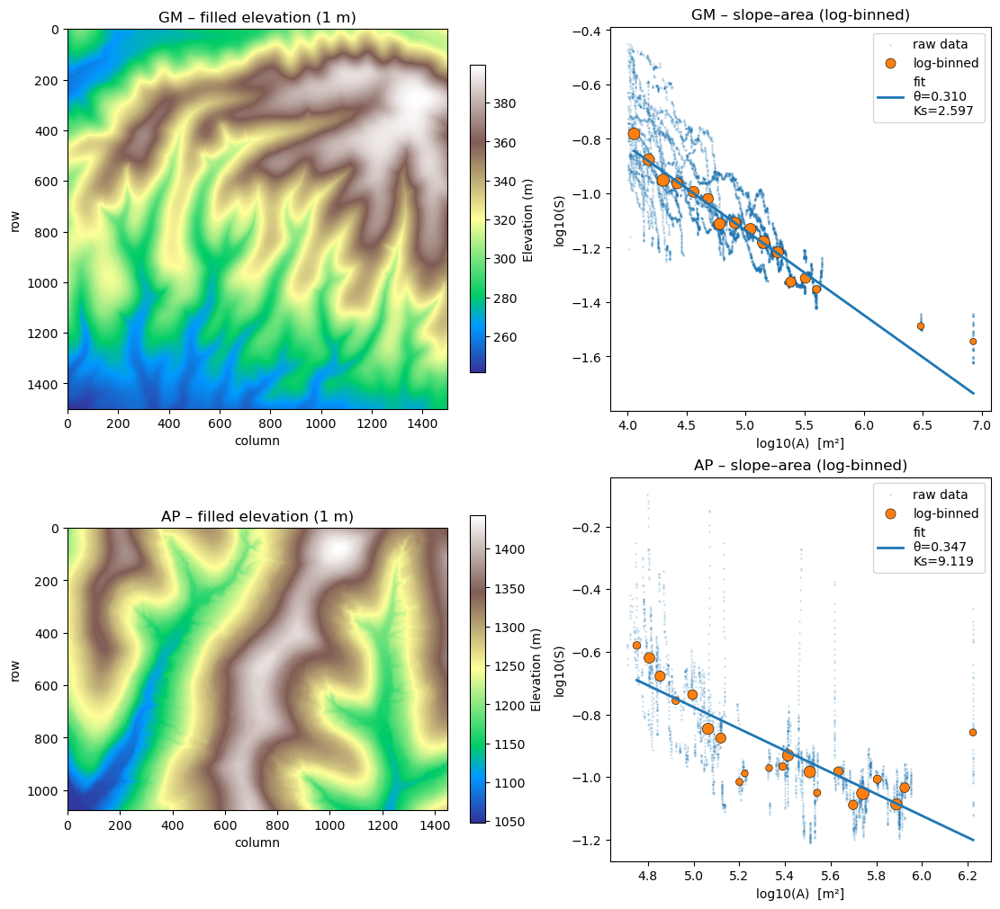

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from TopoAnalysis import dem as d  # TopoAnalysis must be on PYTHONPATH

# ── config ───────────────────────────────────────────────────────────────
tile_dir = Path("data/best_fit_tiles/best_tile_fit_3km/best_tile_fit_3km_extracted_from_full_grids/")
tiles = {
    "GM": dict(prefix="GM_1m_best_fit_3km", theta=0.35, Acrit=1.0e4, fwhm=10, subs=10),
    "AP": dict(prefix="log_binned_results/AP_1m_best_fit",     theta=0.37, Acrit=5.04e4, fwhm=30, subs=30),
}

# ── helpers ──────────────────────────────────────────────────────────────
def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10.0, nbins=24, min_per_bin=10,
    agg="median", require_weighted=True, relax_if_sparse=True
):
    """Fit log10(S) vs log10(A) using log-binned aggregates → (Ks, theta, dbg)."""
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")
    edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            L, R = edges[i], edges[i+1]
            idx = (logA >= L) & (logA < R) if i < nbins - 1 else (logA >= L) & (logA <= R)
            c = int(np.count_nonzero(idx))
            if c < min_required: 
                continue
            a_val = np.median(logA[idx]) if agg == "median" else np.mean(logA[idx])
            s_val = np.median(logS[idx]) if agg == "median" else np.mean(logS[idx])
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return outA, outS, outN

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and len(bA) < 3:
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if len(bA) >= 3:
                break
    if len(bA) < 3:
        raise ValueError("Too few populated bins for regression.")

    bA = np.asarray(bA); bS = np.asarray(bS); w = np.asarray(w, float)
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den == 0:
        raise RuntimeError("Zero variance in binned log10(A).")
    b1 = num / den
    b0 = wy - b1 * wx
    Ks = 10**b0
    theta = -b1
    dbg = dict(logA=logA, logS=logS, bin_logA=bA, bin_logS=bS, bin_counts=w, bin_edges=edges)
    return Ks, theta, dbg


# ── plotting canvas ──────────────────────────────────────────────────────
nrows = len(tiles)
fig, axes = plt.subplots(nrows, 2, figsize=(11, 5*nrows), constrained_layout=True)
if nrows == 1:
    axes = np.array([axes])  # 2-D for uniform indexing

# ── loop over tiles ──────────────────────────────────────────────────────
for row, (tag, cfg) in enumerate(tiles.items()):
    stem = tile_dir / cfg["prefix"]
    fill = d.FilledElevation.load(str(stem) + "_filled")
    area = d.Area.load(           str(stem) + "_area")
    fd   = d.FlowDirectionD8.load(str(stem) + "_fd")

    # ── elevation plot
    ax_e = axes[row, 0]
    im = ax_e.imshow(fill._griddata, cmap="terrain", origin="upper")
    ax_e.set_title(f"{tag} – filled elevation (1 m)")
    ax_e.set_xlabel("column"); ax_e.set_ylabel("row")
    fig.colorbar(im, ax=ax_e, shrink=0.8, label="Elevation (m)")

    # ── slope–area (log-binned) regression
    Ks, theta, dbg = slope_area_regression_binned(
        elev_obj=fill, area_obj=area, fd_obj=fd,
        min_area=cfg["Acrit"],
        vertical_interval=10.0,   # match 30 m workflow smoothing
        nbins=24, min_per_bin=10, agg="median",
        require_weighted=True, relax_if_sparse=True
    )

    # ── slope–area plot: raw + binned + fit
    ax_sa = axes[row, 1]
    logA_raw, logS_raw = dbg["logA"], dbg["logS"]
    ax_sa.scatter(logA_raw, logS_raw, s=1, alpha=0.15, label="raw data")

    bA, bS, bN = dbg["bin_logA"], dbg["bin_logS"], dbg["bin_counts"]
    size = 20 + 80 * (bN / bN.max()) if bN.size and bN.max() > 0 else 40
    ax_sa.scatter(bA, bS, s=size, edgecolor="k", linewidths=0.4, label="log-binned")

    x_fit = np.linspace(bA.min(), bA.max(), 2)
    ax_sa.plot(x_fit, np.log10(Ks) - theta * x_fit, lw=2,
               label=f"fit\nθ={theta:.3f}\nKs={Ks:.3f}")

    ax_sa.set_xlabel("log10(A)  [m²]")
    ax_sa.set_ylabel("log10(S)")
    ax_sa.set_title(f"{tag} – slope–area (log-binned)")
    ax_sa.legend(loc="best", frameon=True)

    # ── console output
    print(f"{tag}: concavity θ = {theta:.3f}   steepness Ks = {Ks:.3f}")

plt.show()


In [34]:
# Taylor-et-al. reference parameters
# Units:
#   curv   : mean hill-top curvature  (negative, m⁻¹)
#   U      : long-term uplift rate    (m Myr⁻¹)
#   K      : fluvial incision coeff.  (m¹⁻²ᵐ  Myr⁻¹)
#   Ks     : U / K                    (m)                ← added
#   D      : diffusivity (m² yr⁻¹)                       ← added
#   Acrit  : drainage-area threshold (m²)
#   theta  : concavity index   (dimensionless)
#
TAYLOR_REF = {
    "GM": dict(
        curv  = -11.8e-3,           # m⁻¹
        U     = 147.0,              # m Myr⁻¹
        K     = 100.2,              # m¹⁻²ᵐ Myr⁻¹
        Ks    = 147.0 / 100.2,      # ≈ 1.467 m
        D     = 124.0 / 1e4,        # 124 cm² yr⁻¹ → 1.24 × 10⁻² m² yr⁻¹
        Acrit = 1.0e4,              # m²
        theta = 0.35
    ),

    "AP": dict(
        curv  = -5.5e-3,            # m⁻¹
        U     = 55.0,               # m Myr⁻¹
        K     = 12.5,               # m¹⁻²ᵐ Myr⁻¹
        Ks    = 55.0 / 12.5,        # 4.400 m
        D     = 100.0 / 1e4,        # 100 cm² yr⁻¹ → 1.00 × 10⁻² m² yr⁻¹
        Acrit = 5.04e4,             # m²
        theta = 0.37
    ),
}


In [37]:
# ----------------------------------------------------------------------
#  FINAL SUMMARY (uses updated TAYLOR_REF with Ks and D fields)
#  • Ks, θ from LOG-BINNED slope–area (vertical_interval = 10 m)
#  • filled == elevation
#  • Area grids normalized to m² to avoid Ks drift
# ----------------------------------------------------------------------
from pathlib import Path
import numpy as np
import copy
from TopoAnalysis import dem as d
import topo_analysis as ta   # for curvature

# ── helpers ──────────────────────────────────────────────────────────────

def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10.0, nbins=24, min_per_bin=10,
    agg="median", require_weighted=True, relax_if_sparse=True
):
    """
    Fit log10(S) vs log10(A) using log-binned aggregates (weighted LS) → (Ks, θ).
    """
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")
    edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            L, R = edges[i], edges[i+1]
            idx = (logA >= L) & (logA < R) if i < nbins-1 else (logA >= L) & (logA <= R)
            c = int(np.count_nonzero(idx))
            if c < min_required:
                continue
            a_val = np.median(logA[idx]) if agg == "median" else np.mean(logA[idx])
            s_val = np.median(logS[idx]) if agg == "median" else np.mean(logS[idx])
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return outA, outS, outN

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and len(bA) < 3:
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if len(bA) >= 3:
                break
    if len(bA) < 3:
        raise ValueError("Too few populated bins for regression.")

    bA = np.asarray(bA); bS = np.asarray(bS); w = np.asarray(w, float)
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den == 0:
        raise RuntimeError("Zero variance in binned log10(A).")

    b1 = num / den
    b0 = wy - b1 * wx
    Ks = 10**b0
    theta = -b1
    return Ks, theta

def block_mean(arr, k):
    ny, nx = arr.shape
    return (arr[:ny//k*k, :nx//k*k]
              .reshape(ny//k, k, nx//k, k)
              .mean(axis=(1, 3)))

# ── paths & config ───────────────────────────────────────────────────────
tile_dir = Path("data/best_fit_tiles/best_tile_fit_3km/best_tile_fit_3km_extracted_from_full_grids/")
tiles = {
    "GM": dict(prefix="GM_1m_best_fit_3km", theta=0.35, Acrit=1.0e4, fwhm=10, subs=10),
    "AP": dict(prefix="log_binned_results/AP_1m_best_fit",     theta=0.37, Acrit=5.04e4, fwhm=30, subs=30),
}

# ── main ─────────────────────────────────────────────────────────────────
for tag, cfg in tiles.items():
    print("\n" + "="*70)
    print(f"{tag}  –  FINAL SUMMARY (updated refs, log-binned Ks/θ)")
    print("="*70)

    # ---- load native 1-m filled DEM, area, FD ------------------------
    stem  = tile_dir / cfg["prefix"]
    fill1 = d.FilledElevation.load(str(stem) + "_filled")  # elevation == filled
    area1 = d.Area.load(           str(stem) + "_area")
    fd1   = d.FlowDirectionD8.load(str(stem) + "_fd")
    area1 = ensure_area_m2(area1)

    # ---- high-resolution Ks, θ via LOG-BINNED fit -------------------
    Acrit = TAYLOR_REF[tag]["Acrit"] if "Acrit" in TAYLOR_REF[tag] else cfg["Acrit"]
    Ks_hr, theta_hr = slope_area_regression_binned(
        fill1, area1, fd1, min_area=Acrit,
        vertical_interval=10.0,          # match 30 m workflow smoothing
        nbins=24, min_per_bin=10, agg="median",
        require_weighted=True, relax_if_sparse=True
    )

    # ---- subsampled grid for diffusivity ----------------------------
    k = cfg["subs"]
    z_sub = block_mean(fill1._griddata, k)
    elev_sub = copy.deepcopy(fill1); elev_sub._griddata = z_sub
    elev_sub._georef_info.dx = elev_sub._georef_info.dy = k
    elev_sub._georef_info.nrows = elev_sub._georef_info.ny  = z_sub.shape[0]
    elev_sub._georef_info.ncols = elev_sub._georef_info.nx  = z_sub.shape[1]

    # recompute flow & area at subsampled scale
    fd_sub   = d.FlowDirectionD8(flooded_dem=elev_sub)
    area_sub = d.Area(flow_direction=fd_sub)

    curv_vals, *_ = ta.extract_hilltop_curvature_first_order(
        elev_sub, area_sub, fd_sub, Acrit, stencil=9
    )
    # D from median hilltop curvature magnitude
    D_med = DATA[tag]["U"] / np.median(curv_vals)

    # ---- pull reference numbers -------------------------------------
    Ks_ref    = TAYLOR_REF[tag]["Ks"]
    theta_ref = TAYLOR_REF[tag]["theta"]
    D_ref     = TAYLOR_REF[tag]["D"]

    # ---- percent differences ----------------------------------------
    err_Ks = 100*(Ks_hr    - Ks_ref)    / Ks_ref
    err_th = 100*(theta_hr - theta_ref) / theta_ref
    err_D  = 100*(D_med    - D_ref)     / D_ref

    # ---- print summary ----------------------------------------------
    print("High-resolution (1 m) regression (log-binned):")
    print(f"  Ks      = {Ks_hr:8.3f} m   (Taylor {Ks_ref:6.3f})   Δ {err_Ks:+6.1f}%")
    print(f"  θ       = {theta_hr:8.3f}     (Taylor {theta_ref:6.3f})   Δ {err_th:+6.1f}%")

    print("\nDiffusivity from subsampled curvature:")
    print(f"  D_med   = {D_med:.2e} m²/yr   (Taylor {D_ref:.2e})   Δ {err_D:+6.1f}%")
    print("-"*70)



GM  –  FINAL SUMMARY (updated refs, log-binned Ks/θ)
High-resolution (1 m) regression (log-binned):
  Ks      =    2.597 m   (Taylor  1.467)   Δ  +77.1%
  θ       =    0.310     (Taylor  0.350)   Δ  -11.3%

Diffusivity from subsampled curvature:
  D_med   = 1.21e-02 m²/yr   (Taylor 1.24e-02)   Δ   -2.3%
----------------------------------------------------------------------

AP  –  FINAL SUMMARY (updated refs, log-binned Ks/θ)
High-resolution (1 m) regression (log-binned):
  Ks      =    9.119 m   (Taylor  4.400)   Δ +107.2%
  θ       =    0.347     (Taylor  0.370)   Δ   -6.1%

Diffusivity from subsampled curvature:
  D_med   = 3.17e-03 m²/yr   (Taylor 1.00e-02)   Δ  -68.3%
----------------------------------------------------------------------


GM: concavity θ = 0.336   steepness Ks = 3.847   (bins used = 24)
AP: concavity θ = 0.549   steepness Ks = 40.040   (bins used = 24)


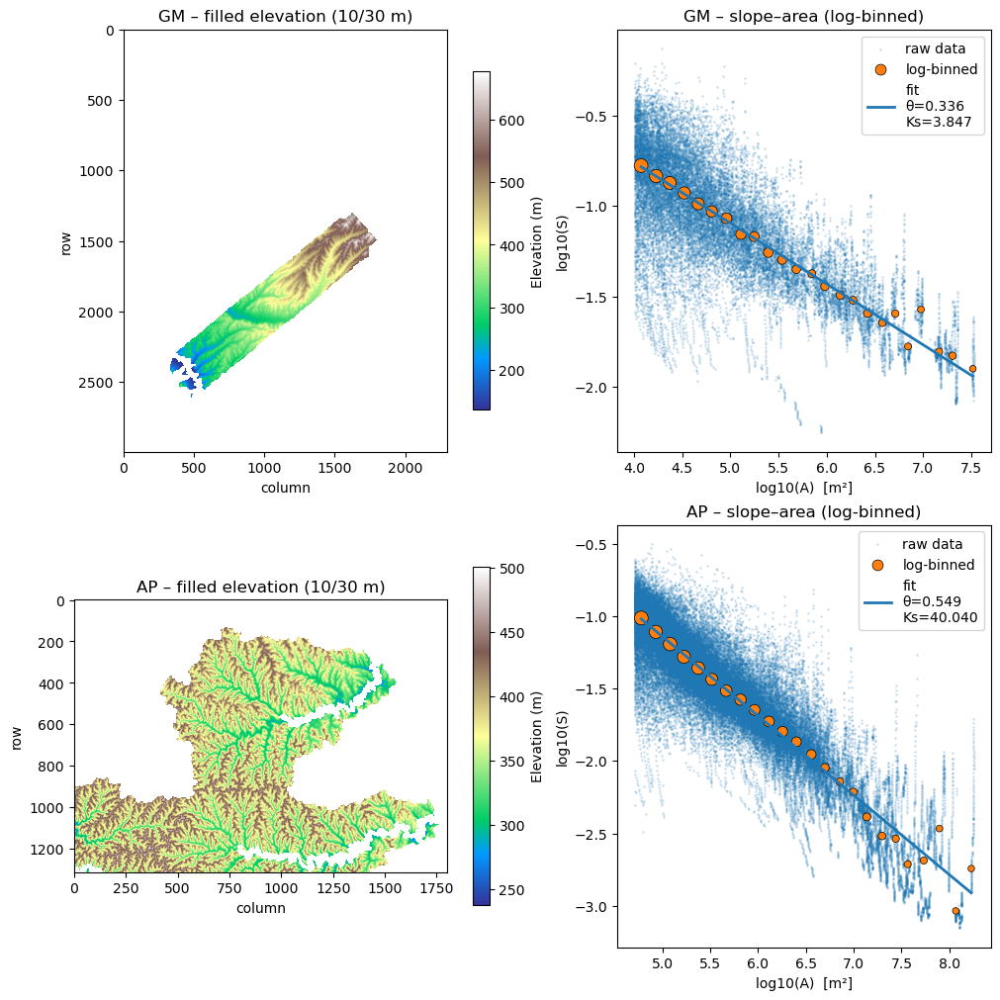

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import linregress              # only used *inside* helper
from TopoAnalysis import dem as d               # TopoAnalysis must be on PYTHONPATH



tile_dir = Path("data/")
tiles = {
    "GM": dict(prefix="GM_Lidar_overlap_10m", theta=0.35, Acrit=1.0e4, fwhm=10, subs=10),
    "AP": dict(prefix="AP_Lidar_overlap_30m", theta=0.37, Acrit=5.04e4, fwhm=30, subs=30),
}

# ----------------------------------------------------------------------
#  Plotting canvas ------------------------------------------------------
nrows = len(tiles)
fig, axes = plt.subplots(nrows, 2, figsize=(10, 5*nrows), constrained_layout=True)
if nrows == 1:
    axes = np.array([axes])  # make 2-D for uniform indexing

# ----------------------------------------------------------------------
#  Loop over tiles ------------------------------------------------------
for row, (tag, cfg) in enumerate(tiles.items()):
    stem = tile_dir / cfg["prefix"]
    fill = d.FilledElevation.load(str(stem) + "_filled")
    area = d.Area.load(str(stem) + "_area")
    fd   = d.FlowDirectionD8.load(str(stem) + "_fd")

    # ---- log-binned slope–area regression ----------------------------
    Ks, theta, dbg = slope_area_regression_binned(
        fill, area, fd, min_area=cfg["Acrit"],
        vertical_interval=10,  # keep your smoothing convention
        nbins=24, min_per_bin=10, agg="median", require_weighted=True
    )

    # ---- elevation plot ----------------------------------------------
    ax_e = axes[row, 0]
    im = ax_e.imshow(fill._griddata, cmap="terrain", origin="upper")
    ax_e.set_title(f"{tag} – filled elevation (10/30 m)")
    ax_e.set_xlabel("column"); ax_e.set_ylabel("row")
    fig.colorbar(im, ax=ax_e, shrink=0.8, label="Elevation (m)")

    # ---- slope–area plot (raw + binned + fit) ------------------------
    ax_sa = axes[row, 1]

    # Raw points (faint)
    ax_sa.scatter(dbg["logA"], dbg["logS"], s=1, alpha=0.15, label="raw data")

    # Binned aggregates
    bA, bS, bN = dbg["bin_logA"], dbg["bin_logS"], dbg["bin_counts"]
    # Scale marker sizes by relative bin count (bounded for visibility)
    if np.max(bN) > 0:
        sizes = 20 + 80 * (bN / np.max(bN))  # min 20, max 100
    else:
        sizes = 40
    ax_sa.scatter(bA, bS, s=sizes, edgecolor="k", linewidths=0.5, label="log-binned")

    # Fit line over the span of binned A (more stable)
    x_min = np.min(bA); x_max = np.max(bA)
    x_fit = np.linspace(x_min, x_max, 2)
    ax_sa.plot(x_fit, np.log10(Ks) - theta * x_fit, lw=2, label=f"fit\nθ={theta:.3f}\nKs={Ks:.3f}")

    ax_sa.set_xlabel("log10(A)  [m²]")
    ax_sa.set_ylabel("log10(S)")
    ax_sa.set_title(f"{tag} – slope–area (log-binned)")
    ax_sa.legend(loc="best", frameon=True)

    # ---- console output ----------------------------------------------
    print(f"{tag}: concavity θ = {theta:.3f}   steepness Ks = {Ks:.3f}   (bins used = {len(bA)})")

plt.show()